# TP2 — Etapa 2: entrenamiento, evaluación y comparación de modelos

En esta notebook evaluamos la búsqueda de imágenes por similitud y comparamos dos
clasificadores de 70 razas. El Modelo A es una ResNet18 preentrenada en ImageNet
y ajustada al dataset. El Modelo B es una CNN diseñada por el equipo y entrenada
desde cero.
Para la búsqueda comparamos los embeddings de ambos modelos con los de una
ResNet18 preentrenada que usamos como baseline.

Para reproducir el trabajo, ejecutá la notebook desde la raíz del repositorio con
el kernel de la `.venv`. Se requieren los manifiestos de `splits/` y las imágenes
aumentadas de `data/dataset/augmented/`, generados por `1-pre-processing.py`.
El procedimiento de auditoría y reparto está en [splits/README.md](splits/README.md).
Para repetir la evaluación, extraé el ZIP en la raíz del repositorio. Por defecto,
la evaluación busca los checkpoints en `models/` y los historiales en
`output/grupos-v1/`. [Descargar modelos e historiales](#13-checkpoints)

## Equipo
- Alejandro Armas
- Gabriel Soda

## 1. Configuración del entorno

La notebook y el script usan los mismos directorios por defecto. Para una
corrida con otras rutas, configurá `MODEL_PATH` y `OUTPUT_PATH` antes de iniciar
el kernel o el script. La salida muestra las rutas efectivas y el dispositivo.

In [4]:
import json
import os
import sys
import time
from pathlib import Path

# Configuración de la entrega antes de importar torch/lib.
os.environ.setdefault("MODEL_PATH", "models")
os.environ.setdefault("OUTPUT_PATH", "output/grupos-v1")
os.environ.setdefault("USE_PGVECTOR", "false")
os.environ.setdefault("TORCH_HOME", str(Path.cwd() / "models" / "torch"))

import altair as alt
import cv2
import numpy as np
import polars as pl
import torch
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "splits").is_dir():
    raise SystemExit("Ejecutá la notebook desde la raíz del repo: falta splits/.")
sys.path.insert(0, str(ROOT / "src"))

from lib.bootstrap import build_classifier, build_similarity
from lib.config import settings
from lib.evaluation.metrics import ndcg_at_k
from lib.schemas import Neighbor

alt.data_transformers.disable_max_rows()

SEED = 42
# 0 = usar todos los datos. Con un valor chico (ej. 5) se hace una prueba rápida de punta a punta.
LIMIT_PER_CLASS = int(os.getenv("LIMIT_PER_CLASS", 0))

COLORS = {
    "primary": "#4c78a8",
    "secondary": "#f58518",
    "negative": "#e45756",
    "positive": "#54a24b",
    "neutral": "#72b7b2",
    "gray": "#b3b3b3",
}
CATEGORICAL_COLORS = [
    COLORS["primary"], COLORS["secondary"], COLORS["negative"], COLORS["positive"],
    COLORS["neutral"], "#f2cf4a", "#9d7660", "#b279a2", "#ff9da6", "#4c78a8",
]

NOMBRES_ES = {
    "split": "partición",
    "breed": "raza",
    "path": "ruta",
    "filename": "archivo",
    "images": "imágenes",
    "metric": "métrica",
    "model": "modelo",
    "strategy": "estrategia",
    "epoch": "época",
    "duration_seconds": "duración (s)",
    "serie": "serie",
    "loss": "loss",
    "value": "valor",
    "accuracy": "exactitud",
    "precision": "precisión",
    "recall": "recall",
    "specificity": "especificidad",
    "f1": "F1",
    "umbral": "umbral",
    "cobertura": "cobertura",
    "rank": "puesto",
    "real": "real",
    "predicha": "predicha",
    "n": "imágenes",
    "proporción": "proporción",
    "support": "imágenes",
    "consulta": "consulta",
    "raza_real": "raza real",
    "raza_vecino": "raza del vecino",
    "score": "score",
    "train_loss": "loss train",
    "valid_loss": "loss valid",
    "train_accuracy": "exactitud train",
    "valid_accuracy": "exactitud valid",
    "valid_f1": "F1 valid",
    "ndcg@10": "NDCG@10",
    "precision@10": "precision@10",
    "precision@1": "precision@1",
}


def inline(df: pl.DataFrame) -> alt.InlineData:
    """Convierte un DataFrame de Polars a InlineData para Altair."""
    return alt.InlineData(values=df.to_dicts())


def mostrar(df: pl.DataFrame) -> None:
    """Muestra un DataFrame con los nombres de columnas en español."""
    display(df.rename({k: v for k, v in NOMBRES_ES.items() if k in df.columns}))


print("dataset:", settings.dataset_path)
print("splits: ", settings.splits_path)
print("modelos:", settings.model_path)
print("salidas:", settings.output_path)
print("dispositivo:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

dataset: data\dataset
splits:  splits
modelos: models
salidas: output\grupos-v1
dispositivo: NVIDIA GeForce RTX 3080 Ti


## 2. Dataset y splits

Después del filtro de calidad, agrupamos las fotos duplicadas y casi duplicadas
confirmadas por la auditoría. Cada grupo completo quedó en una sola partición
para evitar que versiones de la misma foto llegaran a entrenamiento y evaluación.
El reparto de originales apuntó a una proporción de 70/15/15 por raza para
entrenamiento, validación y test.

Aplicamos los aumentos a entrenamiento. Las 10.500 imágenes de `train_augmented`
(150 por raza) sirven tanto para entrenar los clasificadores como para construir
la galería de búsqueda. Validación y test tienen 1.371 imágenes originales cada
uno. En validación seleccionamos los checkpoints y calibramos los umbrales de
búsqueda. Test y el conjunto independiente se usan como consultas de evaluación
y quedan fuera de la galería.

In [5]:
def load_split(name: str) -> pl.DataFrame:
    path = settings.splits_path / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Falta {path}. Ejecutá 1-pre-processing.py.")
    return pl.read_csv(path)


train_df = load_split("train_augmented")
valid_df = load_split("valid")
test_df = load_split("test")

if LIMIT_PER_CLASS:
    print(f"LIMIT_PER_CLASS={LIMIT_PER_CLASS}: submuestra para prueba rápida")
    train_df = train_df.group_by("breed", maintain_order=True).head(LIMIT_PER_CLASS)
    valid_df = valid_df.group_by("breed", maintain_order=True).head(LIMIT_PER_CLASS)
    test_df = test_df.group_by("breed", maintain_order=True).head(LIMIT_PER_CLASS)

splits_long = pl.concat(
    [
        train_df.select("breed").with_columns(pl.lit("train (galería)").alias("split")),
        valid_df.select("breed").with_columns(pl.lit("valid").alias("split")),
        test_df.select("breed").with_columns(pl.lit("test").alias("split")),
    ]
)
resumen_splits = (
    splits_long.group_by(["split", "breed"])
    .len()
    .group_by("split")
    .agg(
        pl.len().alias("razas"),
        pl.col("len").sum().alias("imágenes"),
        pl.col("len").min().alias("mín por raza"),
        pl.col("len").max().alias("máx por raza"),
    )
    .sort("split")
)
mostrar(resumen_splits)

partición,razas,imágenes,mín por raza,máx por raza
str,u32,u32,u32,u32
"""test""",70,1371,12,32
"""train (galería)""",70,10500,150,150
"""valid""",70,1371,12,32


## 3. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

Usamos la ResNet18 preentrenada de `SimilarityService`, con embeddings normalizados
en L2. La galería se construye con `splits/train_augmented.csv`, el mismo manifiesto
que usa la app para indexar. La tabla cruza las consultas de validación, test y el
conjunto independiente con la galería. Los tres controles dieron cero coincidencias
por ruta, por origen de las copias aumentadas y por SHA-256.

Para reproducir la evaluación del baseline, ejecutá las secciones 1 a 3 con
`LIMIT_PER_CLASS=0`.

In [6]:
from hashlib import sha256
from io import BytesIO
from textwrap import fill

from IPython.display import Image, Markdown
from matplotlib.figure import Figure

BASELINE_METRICS = ("cosine", "l2")
BASELINE_K = 10
gallery_df = train_df.sort("breed", maintain_order=True)
independent_df = load_split("independent_manifest").filter(pl.col("scene_type") == "un_perro")


def ruta_clave(value: str) -> str:
    if "://" in value:
        return value
    return os.path.normcase(str((settings.dataset_path / value).resolve()))


indexed_paths = set(map(ruta_clave, gallery_df["path"]))
gallery_origins = {
    ruta_clave(value) for value in gallery_df["origin"] if value and value != "original"
}
if len(indexed_paths) != gallery_df.height:
    raise ValueError("Hay rutas de galería repetidas en train_augmented.csv.")

gallery_identifiers = indexed_paths | gallery_origins
gallery_hashes = {sha256(Path(path).read_bytes()).digest() for path in gallery_identifiers}
split_checks = []
for split, queries in (("valid", valid_df), ("test", test_df), ("independiente", independent_df)):
    query_paths = set(map(ruta_clave, queries["path"]))
    query_origins = {
        ruta_clave(value)
        for column in ("origin", "source")
        if column in queries.columns
        for value in queries[column].drop_nulls()
        if value and value != "original"
    }
    shared_paths = query_paths & gallery_identifiers
    shared_origins = query_origins & gallery_identifiers
    identical_files = sum(
        sha256(Path(path).read_bytes()).digest() in gallery_hashes for path in query_paths
    )
    if len(query_paths) != queries.height or shared_paths or shared_origins or identical_files:
        raise ValueError(
            f"{split}: hay consultas repetidas o presentes en la galería. "
            f"Rutas compartidas: {sorted(shared_paths | shared_origins)}. "
            f"Archivos idénticos: {identical_files}."
        )
    split_checks.append(
        {
            "Partición": split,
            "Imágenes": queries.height,
            "Razas": queries["breed"].n_unique(),
            "Rutas en galería": len(shared_paths),
            "Orígenes en galería": len(shared_origins),
            "Archivos idénticos": identical_files,
        }
    )

print(f"LIMIT_PER_CLASS={LIMIT_PER_CLASS} · ResNet18 · {'CUDA' if torch.cuda.is_available() else 'CPU'}")
display(pl.DataFrame([{
    "Galería": "splits/train_augmented.csv",
    "Imágenes": gallery_df.height,
    "Razas": gallery_df["breed"].n_unique(),
}]))
display(pl.DataFrame(split_checks))

LIMIT_PER_CLASS=0 · ResNet18 · CUDA


Galería,Imágenes,Razas
str,i64,i64
"""splits/train_augmented.csv""",10500,70


Partición,Imágenes,Razas,Rutas en galería,Orígenes en galería,Archivos idénticos
str,i64,i64,i64,i64,i64
"""valid""",1371,70,0,0,0
"""test""",1371,70,0,0,0
"""independiente""",68,20,0,0,0


In [7]:
baseline = build_similarity(settings.model_copy(update={"embedding_model": "baseline"}), store=None)
gallery_paths = gallery_df["path"].to_list()
gallery_breeds = gallery_df["breed"].to_list()
gallery_counts = dict(gallery_df.group_by("breed").len().iter_rows())


def baseline_image(relative_path: str) -> np.ndarray:
    path = (settings.dataset_path / relative_path).resolve()
    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(f"No se pudo leer {path}")
    return image


def embed_baseline(rows: pl.DataFrame, label: str, batch_size: int = 32) -> np.ndarray:
    paths = rows["path"].to_list()
    embeddings = []
    for start in range(0, len(paths), batch_size):
        images = [baseline_image(path) for path in paths[start : start + batch_size]]
        embeddings.extend(baseline.extract_embeddings(images))
    matrix = np.asarray(embeddings, dtype=np.float32)
    print(f"{label}: {len(matrix):,} embeddings de {matrix.shape[1]} dimensiones.", flush=True)
    return matrix


gallery_emb = embed_baseline(gallery_df, "Galería")
gallery_matrix = gallery_emb.astype(np.float64)
gallery_norm2 = np.einsum("ij,ij->i", gallery_matrix, gallery_matrix)


def retrieve_baseline(query_emb: np.ndarray) -> dict[str, list[list[Neighbor]]]:
    """Busca en la galería completa por lotes y puntúa el top con el servicio."""
    rankings = {metric: [] for metric in BASELINE_METRICS}
    for start in range(0, len(query_emb), 128):
        query_batch = query_emb[start : start + 128]
        query_matrix = query_batch.astype(np.float64)
        query_norm2 = np.einsum("ij,ij->i", query_matrix, query_matrix)[:, None]
        dot = query_matrix @ gallery_matrix.T
        cosine = dot / np.sqrt(query_norm2 * gallery_norm2)
        distance2 = query_norm2 + gallery_norm2 - 2 * dot

        for metric, order_by in (("cosine", -cosine), ("l2", distance2)):
            baseline.similarity_metric = metric
            columns = np.argsort(order_by, axis=1, kind="stable")[:, :BASELINE_K]
            for embedding, indices in zip(query_batch, columns, strict=True):
                neighbors = [
                    Neighbor(
                        path=gallery_paths[column],
                        breed=gallery_breeds[column],
                        score=baseline.similarity(embedding, gallery_emb[column]),
                    )
                    for column in indices
                ]
                neighbors.sort(key=lambda neighbor: neighbor.score, reverse=True)
                rankings[metric].append(neighbors)
    return rankings


def predict_baseline(rankings: list[list[Neighbor]], k: int, threshold: float) -> np.ndarray:
    baseline.similarity_threshold = threshold
    return np.array([
        baseline.predict_breed_from_neighbors(neighbors[:k])[0] for neighbors in rankings
    ])


def rank_metrics(rankings: list[list[Neighbor]], breeds: np.ndarray, k: int) -> np.ndarray:
    values = []
    for neighbors, breed in zip(rankings, breeds, strict=True):
        relevance = [float(neighbor.breed == breed) for neighbor in neighbors[:k]]
        ndcg = ndcg_at_k(relevance, k=k, n_relevant=gallery_counts.get(breed, 0))
        values.append((ndcg, sum(relevance) / k))
    return np.asarray(values)

Galería: 10,500 embeddings de 512 dimensiones.


### Calibración en validación

El servicio pondera el voto de cada vecino por su similitud. Probamos umbrales
de 0 a 1 en pasos de 0,001 sobre el score del primer vecino. Si queda por debajo
del umbral, la predicción es `unknown`. Elegimos el umbral que maximiza el F1 de
aciertos aceptados, la media armónica entre la proporción de aciertos sobre las
consultas aceptadas y la proporción de aciertos sobre todas las consultas.
En caso de empate tomamos el umbral más bajo. Como validación contiene razas
conocidas, esta calibración mide la abstención ante posibles errores del voto.

Coseno usa el producto escalar normalizado y L2 usa `1 / (1 + distancia euclídea)`.
En ambas escalas un score más alto indica un vecino más similar. La accuracy
cuenta `unknown` como error. NDCG y precision miden el ranking para todas las consultas.

En las 1.371 consultas de validación, pasar de K=5 a K=10 subió la accuracy
del voto de 88,4026 % a 88,7673 % y el F1 de aciertos aceptados de 0,8843 a
0,8880 con ambas métricas. La precision bajó de 0,8397 a 0,8191 y el NDCG,
de 0,8421 a 0,8269. Los dos valores de K dieron los mismos umbrales,
**0,674 para coseno** y **0,554 para L2**. Cada combinación de métrica y K rechazó una consulta
(0,0729 %) y la accuracy coincidió con la del voto sin rechazo.

In [8]:
valid_rankings = retrieve_baseline(embed_baseline(valid_df, "Validación"))
valid_breeds = valid_df["breed"].to_numpy()
threshold_grid = np.arange(1001) / 1000
calibration_rows = []
baseline_thresholds = {}

for metric, rankings in valid_rankings.items():
    best_scores = np.array([neighbors[0].score for neighbors in rankings])
    accepted = best_scores[None, :] >= threshold_grid[:, None]
    n_accepted = accepted.sum(axis=1)
    for k in (5, BASELINE_K):
        unfiltered = predict_baseline(rankings, k, -np.inf)
        hits = unfiltered == valid_breeds
        n_hits = (accepted & hits).sum(axis=1)
        f1 = 2 * n_hits / (len(valid_breeds) + n_accepted)
        chosen = int(f1.argmax())
        threshold = float(threshold_grid[chosen])
        predicted = predict_baseline(rankings, k, threshold)
        if k == BASELINE_K:
            baseline_thresholds[metric] = threshold

        ndcg, precision = rank_metrics(rankings, valid_breeds, k).mean(axis=0)
        covered = predicted != "unknown"
        calibration_rows.append({
            "Métrica": metric,
            "K": k,
            "Umbral": threshold,
            "NDCG@K": ndcg,
            "precision@K": precision,
            "Accuracy sin rechazo (%)": 100 * hits.mean(),
            "Accuracy (%)": 100 * (predicted == valid_breeds).mean(),
            "Aciertos entre aceptadas (%)": 100 * (predicted[covered] == valid_breeds[covered]).mean(),
            "Unknown (%)": 100 * (~covered).mean(),
            "F1": f1[chosen],
        })

with pl.Config(tbl_cols=-1, float_precision=4):
    display(pl.DataFrame(calibration_rows))

print(f"Umbrales fijados para K={BASELINE_K}: " + ", ".join(
    f"{metric}={threshold:.3f}" for metric, threshold in baseline_thresholds.items()
))

Validación: 1,371 embeddings de 512 dimensiones.


Métrica,K,Umbral,NDCG@K,precision@K,Accuracy sin rechazo (%),Accuracy (%),Aciertos entre aceptadas (%),Unknown (%),F1
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""cosine""",5,0.6740,0.8421,0.8397,88.4026,88.4026,88.4672,0.0729,0.8843
"""cosine""",10,0.6740,0.8269,0.8191,88.7673,88.7673,88.8321,0.0729,0.8880
"""l2""",5,0.5540,0.8421,0.8397,88.4026,88.4026,88.4672,0.0729,0.8843
"""l2""",10,0.5540,0.8269,0.8191,88.7673,88.7673,88.8321,0.0729,0.8880


Umbrales fijados para K=10: cosine=0.674, l2=0.554


### Evaluación final con K=10

Aplicamos los umbrales elegidos en validación. En NDCG@10 la relevancia es binaria
por raza. El ranking ideal se calcula con la cantidad de imágenes de la raza en
toda la galería. Precision@10 es la fracción de vecinos de la raza real entre los
diez recuperados.

Coseno y L2 dieron el mismo orden de vecinos y las mismas predicciones en las
1.371 consultas de test y las 68 independientes. Ambos aceptaron todas las
consultas. Del test al independiente, la accuracy del voto bajó de 89,3508 % a
58,8235 %, NDCG@10 de 0,8374 a 0,5156 y precision@10 de 0,8301 a 0,5059.

In [9]:
baseline_results = {}
baseline_rows = []
for split, queries in (("test", test_df), ("independiente", independent_df)):
    breeds = queries["breed"].to_numpy()
    rankings_by_metric = retrieve_baseline(embed_baseline(queries, split))
    for metric, rankings in rankings_by_metric.items():
        threshold = baseline_thresholds[metric]
        predicted = predict_baseline(rankings, BASELINE_K, threshold)
        ndcg, precision = rank_metrics(rankings, breeds, BASELINE_K).T
        baseline_results[split, metric] = (rankings, predicted, ndcg)
        baseline_rows.append({
            "Conjunto": split,
            "Métrica": metric,
            "Consultas": len(breeds),
            "Umbral": threshold,
            "NDCG@10": ndcg.mean(),
            "precision@10": precision.mean(),
            "Accuracy de raza (%)": 100 * (predicted == breeds).mean(),
            "Unknown (%)": 100 * (predicted == "unknown").mean(),
        })

with pl.Config(tbl_cols=-1, float_precision=4):
    display(pl.DataFrame(baseline_rows))

for split in ("test", "independiente"):
    cosine_ranks, cosine_pred, _ = baseline_results[split, "cosine"]
    l2_ranks, l2_pred, _ = baseline_results[split, "l2"]
    changed_ranks = sum(
        [neighbor.path for neighbor in cosine] != [neighbor.path for neighbor in l2]
        for cosine, l2 in zip(cosine_ranks, l2_ranks, strict=True)
    )
    print(f"{split}: {changed_ranks}/{len(cosine_ranks)} Top-10 con distinto orden, "
          f"{np.count_nonzero(cosine_pred != l2_pred)} predicciones distintas.")

test: 1,371 embeddings de 512 dimensiones.
independiente: 68 embeddings de 512 dimensiones.


Conjunto,Métrica,Consultas,Umbral,NDCG@10,precision@10,Accuracy de raza (%),Unknown (%)
str,str,i64,f64,f64,f64,f64,f64
"""test""","""cosine""",1371,0.6740,0.8374,0.8301,89.3508,0.0000
"""test""","""l2""",1371,0.5540,0.8374,0.8301,89.3508,0.0000
"""independiente""","""cosine""",68,0.6740,0.5156,0.5059,58.8235,0.0000
"""independiente""","""l2""",68,0.5540,0.5156,0.5059,58.8235,0.0000


test: 0/1371 Top-10 con distinto orden, 0 predicciones distintas.
independiente: 0/68 Top-10 con distinto orden, 0 predicciones distintas.


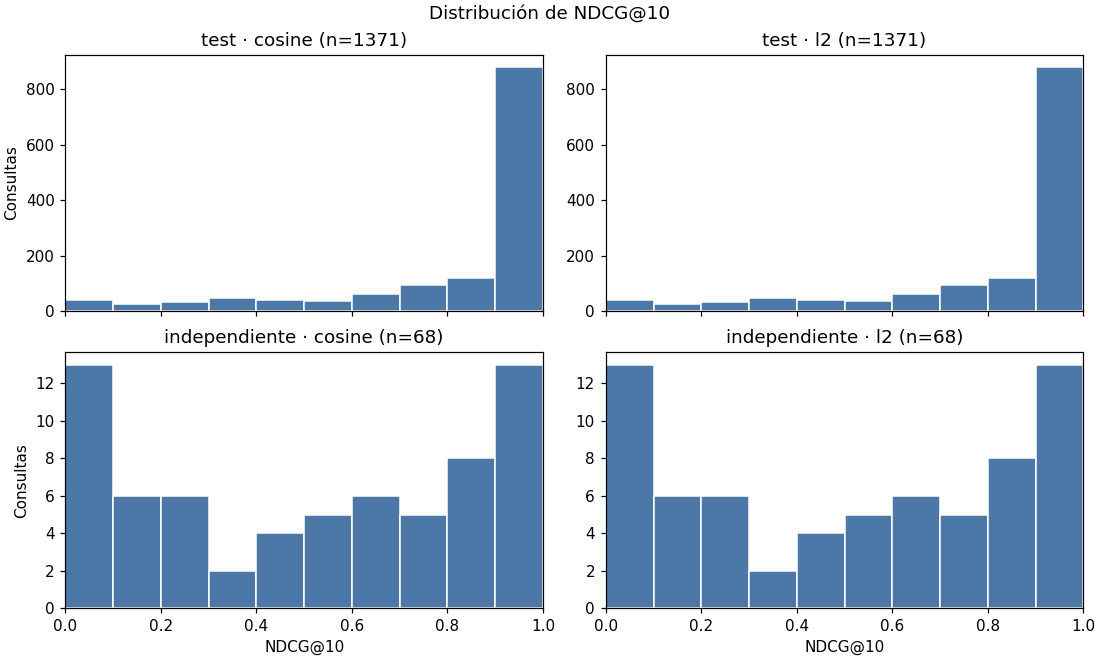

In [10]:
def display_baseline_figure(figure: Figure, title: str) -> None:
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=110)
        display(Image(data=buffer.getvalue(), format="png", alt=title))


distribution = Figure(figsize=(10, 6), layout="constrained")
distribution.suptitle("Distribución de NDCG@10")
for axis, ((split, metric), (_, _, ndcg)) in zip(
    distribution.subplots(2, 2, sharex=True).flat, baseline_results.items(), strict=True
):
    axis.hist(ndcg, bins=np.linspace(0, 1, 11), color=COLORS["primary"], edgecolor="white")
    axis.set(title=f"{split} · {metric} (n={len(ndcg)})", xlim=(0, 1))
for axis in distribution.axes[::2]:
    axis.set_ylabel("Consultas")
for axis in distribution.axes[2:]:
    axis.set_xlabel("NDCG@10")
display_baseline_figure(distribution, "Distribución de NDCG@10 por conjunto y métrica")

### Dos consultas y sus vecinos con coseno

Los vecinos se leen de izquierda a derecha en cada fila. Las etiquetas verdes indican
coincidencia con la raza real.

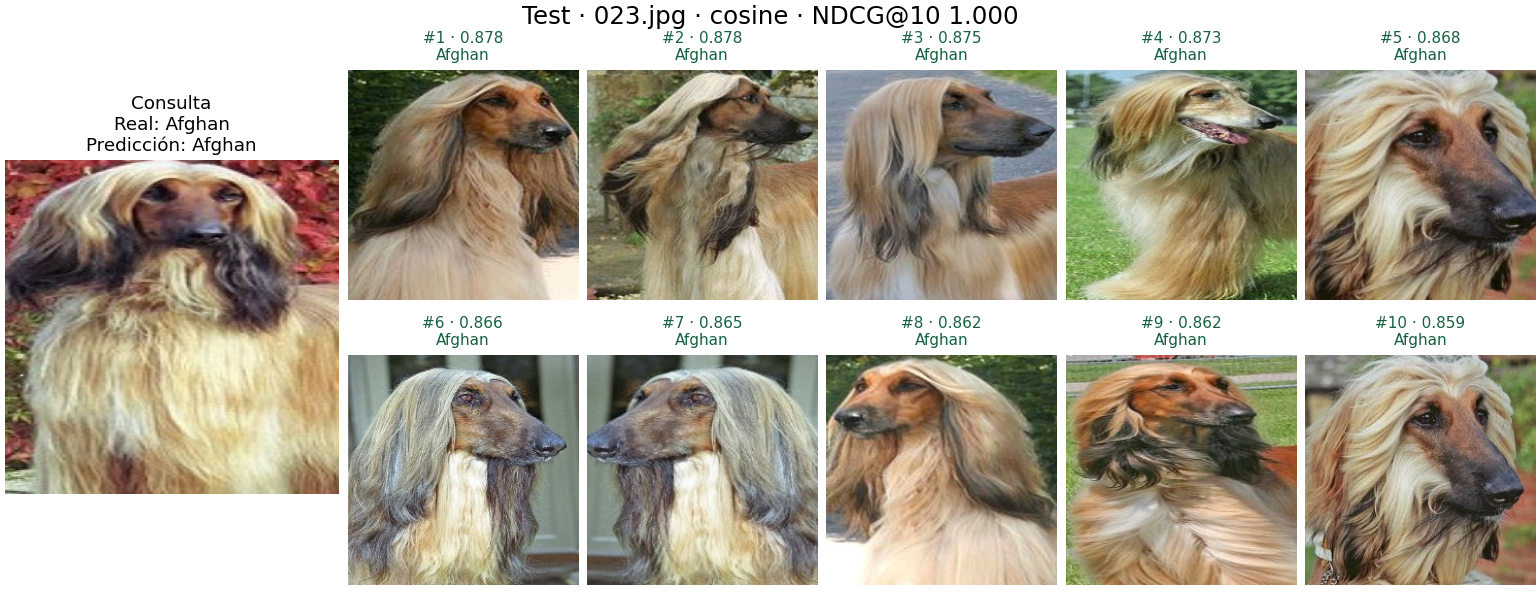

Consulta: train/Afghan/023.jpg


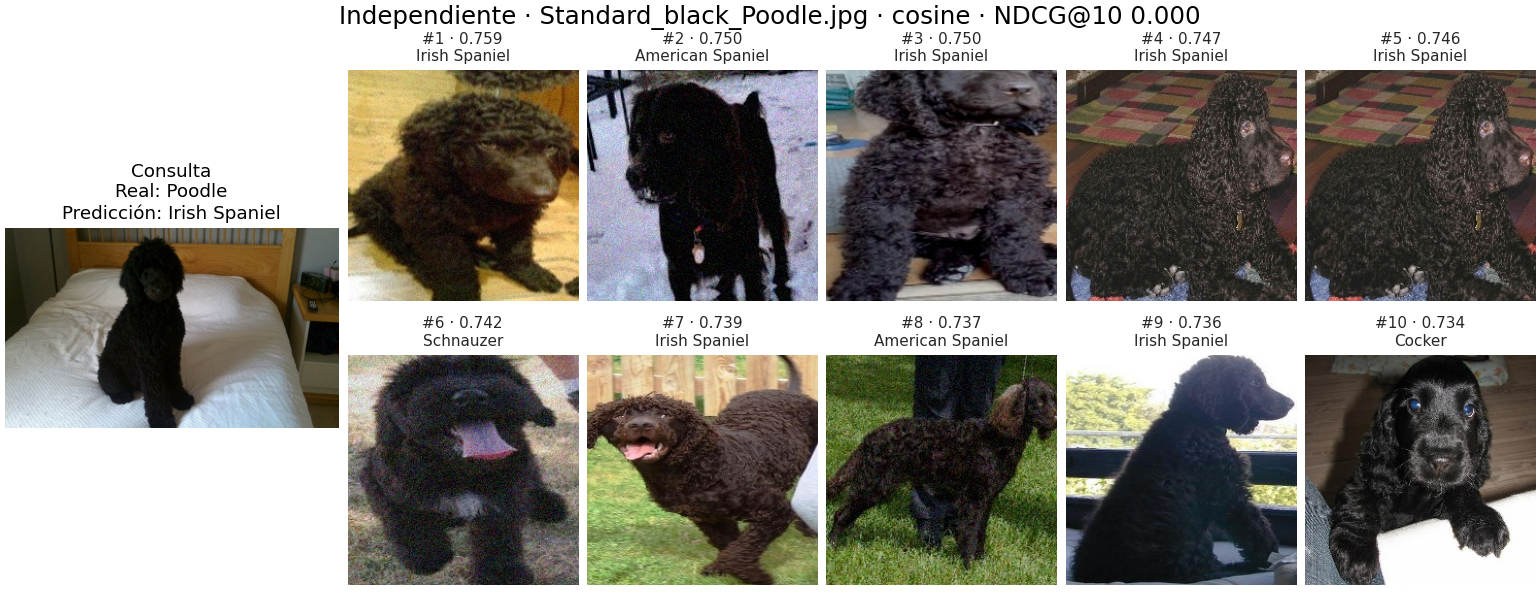

Consulta: independent/Poodle/Standard_black_Poodle.jpg


Foto de la consulta de Dcac410 · [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/) · [Fuente](https://commons.wikimedia.org/wiki/File:Standard_black_Poodle.jpg)

In [11]:
def show_baseline_example(split: str, queries: pl.DataFrame, index: int) -> None:
    rankings, predicted, ndcgs = baseline_results[split, "cosine"]
    query = queries.row(index, named=True)
    title = (
        f"{split.capitalize()} · {query['filename']} · cosine · NDCG@10 {ndcgs[index]:.3f}"
    )
    figure = Figure(figsize=(14, 5.4), layout="constrained")
    figure.suptitle(title, fontsize=16)
    grid = figure.add_gridspec(2, 6, width_ratios=[1.45, 1, 1, 1, 1, 1])
    axis = figure.add_subplot(grid[:, 0])
    axis.imshow(cv2.cvtColor(baseline_image(query["path"]), cv2.COLOR_BGR2RGB))
    axis.set_title(f"Consulta\nReal: {query['breed']}\nPredicción: {predicted[index]}", fontsize=12)
    axis.set_axis_off()
    for position, neighbor in enumerate(rankings[index]):
        axis = figure.add_subplot(grid[position // 5, 1 + position % 5])
        axis.imshow(cv2.cvtColor(baseline_image(neighbor.path), cv2.COLOR_BGR2RGB))
        label = fill(neighbor.breed, width=21)
        axis.set_title(
            f"#{position + 1} · {neighbor.score:.3f}\n{label}", fontsize=10,
            color="#176140" if neighbor.breed == query["breed"] else "#272727",
        )
        axis.set_axis_off()
    display_baseline_figure(figure, title)
    print(f"Consulta: {query['path']}")
    if split == "independiente":
        display(Markdown(
            f"Foto de la consulta de {query['author']} · "
            f"[{query['license']}]({query['license_url']}) · [Fuente]({query['source']})"
        ))


for success, datasets in (
    (True, (("test", test_df), ("independiente", independent_df))),
    (False, (("independiente", independent_df), ("test", test_df))),
):
    for split, queries in datasets:
        _, predicted, ndcg = baseline_results[split, "cosine"]
        candidates = np.flatnonzero((predicted == queries["breed"].to_numpy()) == success)
        if len(candidates):
            index = int(candidates[ndcg[candidates].argmax()] if success else candidates[0])
            show_baseline_example(split, queries, index)
            break

### Qué muestran las consultas

- **Afghan en test.** Los diez vecinos de `train/Afghan/023.jpg` son Afghan.
  El voto acierta y el NDCG@10 es 1,000. La carpeta `train/` indica dónde estaba
  el archivo en el dataset de origen. El manifiesto asigna esta foto a test.
- **Poodle en el independiente.** En `Standard_black_Poodle.jpg`, el perro
  negro está sentado sobre una cama con el hocico en sombra. El primer vecino es
  Irish Spaniel (0,759), que también gana el voto. El top 10 contiene cero
  Poodle y el NDCG@10 es 0,000.

## 6. Modelo A (obligatorio): fine-tuning de ResNet

Partimos de una ResNet18 preentrenada en ImageNet y ajustamos todas sus capas con
`train_augmented`. La cabeza de clasificación combina dropout de `0.2` y
`Linear(512, 70)`. Para extraer embeddings usamos los 512 componentes del pooling
global, antes de la cabeza. La entrada es de 224×224 con normalización de ImageNet.

Entrenamos con AdamW, `CosineAnnealingLR` y *label smoothing*. En la tabla de
entrenamiento se muestran las métricas de cada época. Guardamos como checkpoint
el modelo que obtuvo el mayor F1 macro de validación.

In [12]:
classifier = build_classifier(settings)
classifier.set_active_model("resnet18_finetuned")
classifier.train_classifier()

c:\Users\Gabi\Proyectos\tuia-dog-recognition-app\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:lib.services.classifier_service:Entrenando resnet18_finetuned: 10500 train | 1371 valid | 70 clases | cuda (full)
INFO:lib.services.classifier_service:época 01 | train loss 1.7979 acc 0.700 | valid loss 1.4889 acc 0.775 f1 0.777 | 35.8 s
INFO:lib.services.classifier_service:época 02 | train loss 1.2346 acc 0.874 | valid loss 1.4053 acc 0.792 f1 0.792 | 34.5 s
INFO:lib.services.classifier_service:época 03 | train loss 1.1022 acc 0.922 | valid loss 1.3172 acc 0.842 f1 0.840 | 33.9 s
INFO:lib.services.classifier_service:época 04 | train loss 1.0142 acc 0.953 | valid loss 1.3046 acc 0.832 f1 0.835 | 34.6 s
INFO:lib.services.classifier_service:época 05 | train loss 0.9541 acc 0.972 | valid loss 1.2450 acc 0.851 f

In [13]:
def load_history(model_name: str) -> pl.DataFrame | None:
    """Historial de `train_classifier`, o None si se reutilizó el checkpoint y no hay JSON."""
    path = settings.output_path / f"history_{model_name}.json"
    if not path.is_file():
        print(f"Sin historial para {model_name}: se reutilizó el checkpoint existente.")
        return None
    return pl.DataFrame(json.loads(path.read_text(encoding="utf-8"))["epochs"])


history = load_history("resnet18_finetuned")
if history is not None:
    mostrar(history)

época,duración (s),loss train,exactitud train,loss valid,exactitud valid,F1 valid
i64,f64,f64,f64,f64,f64,f64
1,35.83,1.797861,0.699905,1.488864,0.775346,0.777497
2,34.52,1.234608,0.873714,1.40529,0.792123,0.79168
3,33.92,1.102185,0.921524,1.31717,0.841721,0.840348
4,34.6,1.014242,0.952952,1.304648,0.83151,0.834852
5,33.34,0.954099,0.971714,1.245026,0.851204,0.850048
…,…,…,…,…,…,…
8,34.65,0.859712,0.993143,1.184464,0.875274,0.875518
9,33.79,0.839884,0.99581,1.158836,0.883297,0.883435
10,32.95,0.826075,0.997905,1.15904,0.884756,0.886169


In [14]:
metrics_a = classifier.evaluate_classifier()
evaluation_a = classifier.last_evaluation
(settings.output_path / "eval_resnet18_finetuned.json").write_text(
    json.dumps(evaluation_a, ensure_ascii=False, indent=2), encoding="utf-8"
)
mostrar(
    pl.DataFrame(
        [{"métrica": key, "valor": round(float(value), 4)} for key, value in metrics_a.items()]
    )
)

INFO:lib.services.classifier_service:Evaluación resnet18_finetuned: {'accuracy': 0.9029905178701677, 'precision': 0.9124337516375446, 'recall': 0.9047695439951632, 'specificity': 0.9985918584551848, 'f1': 0.9041598664274344}


métrica,valor
str,f64
"""accuracy""",0.903
"""precision""",0.9124
"""recall""",0.9048
"""specificity""",0.9986
"""f1""",0.9042


### Curvas de entrenamiento y matriz de confusión (Modelo A)

La ResNet completó 12 épocas. El F1 macro de validación subió de 77,75 % en la primera
a un máximo de **88,62 % en la época 10**, que es la del checkpoint evaluado.
Entre las épocas 10 y 12, la pérdida de entrenamiento siguió bajando de 0,826 a 0,815
y el F1 macro de validación terminó en 88,36 %. En la última época, la accuracy fue
99,77 % en entrenamiento y 88,26 % en validación. La brecha y el descenso del F1
después del máximo son indicios de sobreajuste al final del entrenamiento.

En test, la confusión más frecuente fue predecir Shih-Tzu en 16 fotos de Lhasa.
Lhasa fue además la raza con menor exactitud del Modelo A, con 9 aciertos entre
27 fotos.

In [15]:
def plot_training(history: pl.DataFrame, model: str) -> None:
    """Curvas de loss y accuracy. Train siempre azul, validación siempre naranja."""
    color = alt.Color(
        "split:N",
        title=None,
        scale=alt.Scale(
            domain=["train", "valid"],
            range=[COLORS["primary"], COLORS["secondary"]],
        ),
    )

    def long_frame(columns: list[str], value_name: str) -> pl.DataFrame:
        return (
            history.select(["epoch", *columns])
            .unpivot(index="epoch", variable_name="serie", value_name=value_name)
            .with_columns(
                pl.when(pl.col("serie").str.starts_with("train"))
                .then(pl.lit("train"))
                .otherwise(pl.lit("valid"))
                .alias("split")
            )
        )

    loss_chart = (
        alt.Chart(inline(long_frame(["train_loss", "valid_loss"], "loss")))
        .mark_line(point=True)
        .encode(
            x=alt.X("epoch:Q", title="Época"),
            y=alt.Y("loss:Q", title="Loss"),
            color=color,
            tooltip=["epoch:Q", "split:N", alt.Tooltip("loss:Q", format=".4f")],
        )
        .properties(width=520, height=300, title=f"{model} — loss: train vs validación")
    )

    accuracy_chart = (
        alt.Chart(inline(long_frame(["train_accuracy", "valid_accuracy"], "accuracy")))
        .mark_line(point=True)
        .encode(
            x=alt.X("epoch:Q", title="Época"),
            y=alt.Y("accuracy:Q", title="Accuracy", axis=alt.Axis(format="%")),
            color=color,
            tooltip=["epoch:Q", "split:N", alt.Tooltip("accuracy:Q", format=".3f")],
        )
        .properties(width=520, height=300, title=f"{model} — accuracy: train vs validación")
    )
    display(loss_chart | accuracy_chart)


if history is not None:
    plot_training(history, "Modelo A")

alt.HConcatChart(...)

In [16]:
def plot_confusion(evaluation: dict, model: str, top_pairs: int = 15, worst: int = 10) -> None:
    """Matriz de confusión normalizada + pares más confundidos + peores razas."""
    labels = evaluation["class_names"]
    matrix = np.asarray(evaluation["confusion_matrix"], dtype=float)
    normalized = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)
    long = pl.DataFrame(
        {
            "real": np.repeat(labels, len(labels)),
            "predicha": np.tile(labels, len(labels)),
            "n": matrix.reshape(-1).astype(int),
            "proporción": np.round(normalized.reshape(-1), 4),
        }
    ).filter(pl.col("n") > 0)
    chart = (
        alt.Chart(inline(long))
        .mark_rect()
        .encode(
            x=alt.X("predicha:N", sort=labels, title=None, axis=alt.Axis(labelAngle=-90, labelFontSize=6)),
            y=alt.Y("real:N", sort=labels, title=None, axis=alt.Axis(labelFontSize=6)),
            color=alt.Color(
                "proporción:Q",
                title="Proporción",
                scale=alt.Scale(range=["#ffffff", COLORS["primary"]]),
            ),
            tooltip=[
                alt.Tooltip("real:N", title="Real"),
                alt.Tooltip("predicha:N", title="Predicha"),
                alt.Tooltip("n:Q", title="Imágenes"),
                alt.Tooltip("proporción:Q", format=".1%"),
            ],
        )
        .properties(width=760, height=680, title=f"Matriz de confusión normalizada ({model})")
    )
    display(chart)

    off_diagonal = matrix.copy()
    np.fill_diagonal(off_diagonal, 0)
    pairs = [
        {"real": labels[row], "predicha": labels[column], "n": int(off_diagonal[row, column])}
        for row, column in zip(*np.nonzero(off_diagonal))
    ]
    if pairs:
        mostrar(pl.DataFrame(pairs).sort("n", descending=True).head(top_pairs))
    mostrar(pl.DataFrame(evaluation["per_class"]).sort("accuracy").head(worst))


plot_confusion(evaluation_a, "Modelo A")

alt.Chart(...)

real,predicha,imágenes
str,str,i64
"""Lhasa""","""Shih-Tzu""",16
"""American Spaniel""","""Irish Spaniel""",4
"""Bulldog""","""Boston Terrier""",4
"""Borzoi""","""Border Collie""",3
"""French Bulldog""","""Bulldog""",3
…,…,…
"""Boston Terrier""","""French Bulldog""",2
"""Collie""","""Border Collie""",2
"""Corgi""","""Pomeranian""",2


raza,imágenes,exactitud
str,i64,f64
"""Lhasa""",27,0.333333
"""American Spaniel""",15,0.6
"""Borzoi""",19,0.631579
"""Siberian Husky""",15,0.666667
"""Great Dane""",21,0.714286
"""Labradoodle""",18,0.722222
"""American Hairless""",12,0.75
"""French Bulldog""",16,0.75
"""Corgi""",20,0.8


## 7. Modelo B (obligatorio): CNN propia

Entrenamos la CNN desde cero y actualizamos todas sus capas. Recibe imágenes de
224×224 con normalización de ImageNet y clasifica las mismas 70 razas.

| Componente | Configuración |
|---|---|
| Bloques convolucionales | 4 bloques con dos capas Conv-BatchNorm-ReLU y un MaxPool por bloque. Los canales pasan de 32 a 64, 128 y 256. |
| Pooling global promedio | Resume cada uno de los 256 canales en un valor. |
| Embedding | `Linear(256, 512)` seguida de ReLU. |
| Cabeza de clasificación | Dropout de `0.2` antes de `Linear(512, 70)`. |

La arquitectura está en `src/lib/models/modelo_b_cnn.py`.
En la corrida definitiva usamos AdamW con tasa inicial `3e-4`, `weight_decay=1e-4`,
`CosineAnnealingLR`, *label smoothing* de `0.1` y lotes de 32 imágenes.

### Experimentos registrados

| Prueba | Pregunta | Configuración | Partición | Observación | Decisión |
| --- | --- | --- | --- | --- | --- |
| Prueba local de CUDA | ¿La CNN puede completar una época con validación en GPU? | CNN desde cero, CUDA, 1 época, lote de 32 | `train_augmented` y `valid` anteriores al reparto por grupos | La época con validación terminó en 47,53 s y dejó un checkpoint y su historial. | Usar CUDA para el entrenamiento definitivo. La prueba sirve como comprobación técnica. |
| Corrida definitiva | ¿Qué rendimiento alcanza la CNN desde cero con el reparto por grupos? | Misma arquitectura, CUDA, hasta 12 épocas, lote de 32. Selección por F1 macro en `valid`. | Entrenamiento en `train_augmented`, selección en `valid` y evaluación en `test`, todos definitivos | El F1 macro de validación llegó a su máximo en la época 12. | Conservar ese checkpoint para evaluar la CNN y compararla con la ResNet bajo el mismo protocolo. |

El historial de la primera prueba está en `output/cuda-prueba-20261126-212552/history_cnn_custom.json`.
El de la segunda se distribuye como `output/grupos-v1/history_cnn_custom.json`.
[Registro de particiones y checkpoints](splits/README.md#checkpoints-evaluados-y-pesos-anteriores).

Los repartos difieren, así que una comparación de métricas entre las dos corridas
mezclaría el efecto de la partición con el de las épocas. El registro también conserva
el hash de otro checkpoint anterior. Las dos corridas de la tabla son las que cuentan
con historial por época para esta arquitectura.

In [17]:
classifier.set_active_model("cnn_custom")
classifier.train_classifier()

INFO:lib.services.classifier_service:Entrenando cnn_custom: 10500 train | 1371 valid | 70 clases | cuda (full)
INFO:lib.services.classifier_service:época 01 | train loss 3.9816 acc 0.062 | valid loss 3.9052 acc 0.079 f1 0.042 | 35.6 s
INFO:lib.services.classifier_service:época 02 | train loss 3.6356 acc 0.133 | valid loss 3.6623 acc 0.131 f1 0.085 | 35.4 s
INFO:lib.services.classifier_service:época 03 | train loss 3.4155 acc 0.182 | valid loss 3.4100 acc 0.181 f1 0.145 | 35.6 s
INFO:lib.services.classifier_service:época 04 | train loss 3.2595 acc 0.217 | valid loss 3.2752 acc 0.224 f1 0.197 | 35.6 s
INFO:lib.services.classifier_service:época 05 | train loss 3.1235 acc 0.254 | valid loss 3.1328 acc 0.246 f1 0.212 | 35.4 s
INFO:lib.services.classifier_service:época 06 | train loss 3.0177 acc 0.288 | valid loss 3.1950 acc 0.231 f1 0.204 | 35.6 s
INFO:lib.services.classifier_service:época 07 | train loss 2.9043 acc 0.314 | valid loss 3.2195 acc 0.234 f1 0.206 | 35.4 s
INFO:lib.services.cla

In [18]:
metrics_b = classifier.evaluate_classifier()
evaluation_b = classifier.last_evaluation
(settings.output_path / "eval_cnn_custom.json").write_text(
    json.dumps(evaluation_b, ensure_ascii=False, indent=2), encoding="utf-8"
)
mostrar(
    pl.DataFrame(
        [{"métrica": key, "valor": round(float(value), 4)} for key, value in metrics_b.items()]
    )
)

INFO:lib.services.classifier_service:Evaluación cnn_custom: {'accuracy': 0.3770970094821298, 'precision': 0.36028707667607707, 'recall': 0.39216308343483935, 'specificity': 0.9909744800919563, 'f1': 0.35212024806995235}


métrica,valor
str,f64
"""accuracy""",0.3771
"""precision""",0.3603
"""recall""",0.3922
"""specificity""",0.991
"""f1""",0.3521


### Curvas de entrenamiento y matriz de confusión (Modelo B)

Cada fila del historial es una observación de la **misma corrida definitiva**.
La pérdida de entrenamiento bajó durante toda la corrida. La de validación repuntó
en las épocas 6 y 7 y luego bajó hasta su mínimo al final. La accuracy mejoró en
ambas particiones y terminó en 41,55 % en entrenamiento y 37,20 % en validación.
El F1 macro de validación pasó de 33,31 % en la época 10 a 34,71 % en la 11 y
alcanzó su máximo de **34,83 % en la época 12**.

La CNN todavía mejoraba al agotarse el presupuesto de épocas, con una ganancia
pequeña al final. Una corrida más larga con el mismo reparto permitiría probar si
esa mejora continúa. Con el protocolo evaluado, la ResNet obtuvo mayor F1 macro
en test y en el conjunto independiente, por lo que la elegimos para clasificar.
La capacidad de los modelos y el preentrenamiento son posibles factores de esa
diferencia. Para medir el aporte de cada uno haría falta variar un factor por vez.
[Comparación final](#12-comparación-y-elección-final).

En test, la confusión más frecuente fue predecir Boston Terrier en 10 fotos de
Bulldog. La tabla por raza muestra cero aciertos en Borzoi, Corgi y Great Dane.

In [4]:
history_b = load_history("cnn_custom")
if history_b is not None:
    with pl.Config(tbl_rows=-1):
        mostrar(history_b)
    plot_training(history_b, "Modelo B")

época,duración (s),loss train,exactitud train,loss valid,exactitud valid,F1 valid
i64,f64,f64,f64,f64,f64,f64
1,35.64,3.981603,0.062476,3.905159,0.078775,0.041802
2,35.39,3.635555,0.132952,3.66232,0.130562,0.084532
3,35.57,3.415472,0.181524,3.410039,0.18089,0.145498
4,35.56,3.259543,0.217238,3.27524,0.223924,0.196536
5,35.4,3.123529,0.253524,3.132822,0.245806,0.21172
6,35.56,3.01768,0.28781,3.195036,0.231218,0.204118
7,35.38,2.904337,0.314095,3.219503,0.234136,0.205805
8,35.58,2.812865,0.346476,3.008251,0.280817,0.250528
9,35.45,2.73805,0.372762,2.879933,0.322392,0.29139


alt.HConcatChart(...)

In [20]:
plot_confusion(evaluation_b, "Modelo B")

alt.Chart(...)

real,predicha,imágenes
str,str,i64
"""Bulldog""","""Boston Terrier""",10
"""Labradoodle""","""Cockapoo""",8
"""Chow""","""Pomeranian""",7
"""Cocker""","""Cockapoo""",7
"""African Wild Dog""","""Malinois""",6
…,…,…
"""Bichon Frise""","""Maltese""",5
"""Doberman""","""Rottweiler""",5
"""Great Dane""","""Mex Hairless""",5


raza,imágenes,exactitud
str,i64,f64
"""Borzoi""",19,0.0
"""Corgi""",20,0.0
"""Great Dane""",21,0.0
"""Labrador""",27,0.037037
"""Pug""",25,0.04
"""Poodle""",20,0.05
"""Chihuahua""",19,0.052632
"""Greyhound""",19,0.052632
"""Lhasa""",27,0.074074


## 8. Evaluación sobre el conjunto independiente

Usamos las 68 fotos etiquetadas `un_perro` en el manifiesto independiente.
Cada consulta es una foto completa con la raza del perro como referencia.
Las métricas macro dan el mismo peso a cada una de las **20 razas presentes en
las etiquetas reales**. La accuracy es la proporción de fotos clasificadas correctamente.

- **ResNet18 (Modelo A).** La accuracy bajó de 90,30 % en test a 50,00 % en el
  independiente (34/68).
- **CNN (Modelo B).** La accuracy bajó de 37,71 % en test a 11,76 % en el
  independiente (8/68).

Las diferencias de fondo, iluminación y encuadre son una posible explicación.
En la foto del Poodle negro de la sección 3, gran parte de la imagen es la cama y
el hocico queda en sombra. Los dos clasificadores también se equivocaron en esa
foto según sus predicciones guardadas. Las diferencias en las razas representadas
pueden contribuir a la caída. Con estas 68 fotos, queda abierta la contribución
de cada factor.

In [21]:
independent = load_split("independent_manifest")
independent_eval = (
    independent.filter(pl.col("scene_type") == "un_perro")
    .select(["breed", "path"])
    .with_columns(pl.lit("independiente").alias("split"))
    .select(["split", "breed", "path"])
)
independent_eval.write_csv(settings.splits_path / "independent_eval.csv")
mostrar(independent_eval.group_by("breed").len().sort("breed"))

raza,len
str,u32
"""American Hairless""",3
"""American Spaniel""",3
"""Beagle""",4
"""Bearded Collie""",3
"""Blenheim""",2
…,…
"""Mex Hairless""",3
"""Pekinese""",3
"""Pomeranian""",3


In [22]:
independent_metrics = {}
for model_name in ("resnet18_finetuned", "cnn_custom"):
    classifier.set_active_model(model_name)
    independent_metrics[model_name] = classifier.evaluate_classifier("independent_eval")
    (settings.output_path / f"eval_independent_{model_name}.json").write_text(
        json.dumps(classifier.last_evaluation, ensure_ascii=False, indent=2), encoding="utf-8"
    )

with pl.Config(tbl_cols=-1, float_precision=4):
    display(
        pl.DataFrame(
            [{"Modelo": name, **metrics} for name, metrics in independent_metrics.items()]
        )
    )

INFO:lib.services.classifier_service:Evaluación resnet18_finetuned: {'accuracy': 0.5, 'precision': 0.7, 'recall': 0.5208333333333333, 'specificity': 0.9922716346153846, 'f1': 0.571904761904762}
INFO:lib.services.classifier_service:Evaluación cnn_custom: {'accuracy': 0.11764705882352941, 'precision': 0.29500000000000004, 'recall': 0.125, 'specificity': 0.9838341346153847, 'f1': 0.15999999999999998}


Modelo,accuracy,precision,recall,specificity,f1
str,f64,f64,f64,f64,f64
"""resnet18_finetuned""",0.5000,0.7000,0.5208,0.9923,0.5719
"""cnn_custom""",0.1176,0.2950,0.1250,0.9838,0.1600


## 9. Embeddings de los modelos entrenados

Comparamos el baseline y los modelos A y B como extractores con la misma galería,
las mismas consultas y similitud coseno. Usamos K=10 y compartimos el umbral de
0,674 calibrado con los embeddings del baseline en validación. La tabla separa
las métricas del ranking (NDCG@10 y precision@10) de las del voto (accuracy y F1 macro).

In [41]:
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score, silhouette_score


def embed_rows(extractor, rows: pl.DataFrame, label: str, batch_size: int = 32) -> np.ndarray:
    """Embeddings L2-normalizados de un manifiesto, en lotes."""
    paths = rows["path"].to_list()
    embeddings = []
    for start in range(0, len(paths), batch_size):
        images = [baseline_image(path) for path in paths[start : start + batch_size]]
        embeddings.extend(extractor(images))
        print(f"  {label}: {min(start + batch_size, len(paths))}/{len(paths)}", end="\r")
    print(f"  {label}: {len(paths)} embeddings")
    return np.asarray(embeddings, dtype=np.float32)


def retrieval_metrics(
    query_emb: np.ndarray,
    query_breeds: list[str],
    gallery_matrix: np.ndarray,
    *,
    k: int,
    threshold: float,
) -> tuple[float, float, float, list[str]]:
    """Calcula las métricas del ranking coseno y del voto con el umbral indicado."""
    voter = build_similarity(
        settings.model_copy(update={
            "similarity_metric": "cosine", "top_k": k, "similarity_threshold": threshold,
        }),
        store=None,
    )
    cosine = np.clip(query_emb @ gallery_matrix.T, -1.0, 1.0)
    order = np.argsort(-cosine, axis=1)[:, :k]
    ndcgs, precisions, predicted = [], [], []
    for index, breed in enumerate(query_breeds):
        neighbors = [
            Neighbor(
                path=gallery_paths[column],
                breed=gallery_breeds[column],
                score=float(cosine[index, column]),
            )
            for column in order[index]
        ]
        predicted.append(voter.predict_breed_from_neighbors(neighbors)[0])
        relevance = [float(gallery_breeds[column] == breed) for column in order[index]]
        ndcgs.append(ndcg_at_k(relevance, k=k, n_relevant=gallery_counts.get(breed, 0)))
        precisions.append(float(np.mean(relevance)))
    accuracy = float(np.mean(np.asarray(predicted) == np.asarray(query_breeds)))
    return float(np.mean(ndcgs)), float(np.mean(precisions)), accuracy, predicted

In [24]:
baseline_test = embed_baseline(test_df, "Test baseline")
baseline_independent = embed_baseline(independent_eval, "Independiente baseline")

classifier.set_active_model("resnet18_finetuned")
gallery_a = embed_rows(classifier.extract_custom_embeddings, gallery_df, "Galería A")
test_a = embed_rows(classifier.extract_custom_embeddings, test_df, "Test A")
independent_a = embed_rows(classifier.extract_custom_embeddings, independent_eval, "Independiente A")

classifier.set_active_model("cnn_custom")
gallery_b = embed_rows(classifier.extract_custom_embeddings, gallery_df, "Galería B")
test_b = embed_rows(classifier.extract_custom_embeddings, test_df, "Test B")
independent_b = embed_rows(classifier.extract_custom_embeddings, independent_eval, "Independiente B")

Test baseline: 1,371 embeddings de 512 dimensiones.
Independiente baseline: 68 embeddings de 512 dimensiones.
  Galería A: 10500 embeddings
  Test A: 1371 embeddings
  Independiente A: 68 embeddings
  Galería B: 10500 embeddings
  Test B: 1371 embeddings
  Independiente B: 68 embeddings


In [42]:
retrieval_threshold = baseline_thresholds["cosine"]
gallery_by_model = {"baseline": gallery_emb, "Modelo A": gallery_a, "Modelo B": gallery_b}
embeddings_by_model = {
    "baseline": (baseline_test, baseline_independent),
    "Modelo A": (test_a, independent_a),
    "Modelo B": (test_b, independent_b),
}
retrieval_rows = []
for name, (test_embedding, independent_embedding) in embeddings_by_model.items():
    for split, embedding, breeds in (
        ("test", test_embedding, test_df["breed"].to_list()),
        ("independiente", independent_embedding, independent_eval["breed"].to_list()),
    ):
        ndcg, precision, accuracy, predicted = retrieval_metrics(
            embedding, breeds, gallery_by_model[name], k=BASELINE_K, threshold=retrieval_threshold
        )
        # Macro sobre las razas presentes, igual que el clasificador.
        f1 = f1_score(
            breeds, predicted, labels=sorted(set(breeds)), average="macro", zero_division=0
        )
        retrieval_rows.append(
            {
                "Embeddings": name,
                "Conjunto": split,
                "NDCG@10": ndcg,
                "precision@10": precision,
                "Accuracy de raza (%)": 100 * accuracy,
                "F1 macro (%)": 100 * f1,
            }
        )
print(f"Métrica: cosine | K: {BASELINE_K} | Umbral: {retrieval_threshold:.3f}")
print(f"Consultas por extractor: {test_df.height} de test y {independent_eval.height} independientes.")
with pl.Config(tbl_cols=-1, float_precision=4):
    display(pl.DataFrame(retrieval_rows))

Métrica: cosine | K: 10 | Umbral: 0.674
Consultas por extractor: 1371 de test y 68 independientes.


Embeddings,Conjunto,NDCG@10,precision@10,Accuracy de raza (%),F1 macro (%)
str,str,f64,f64,f64,f64
"""baseline""","""test""",0.8374,0.8301,89.3508,89.1185
"""baseline""","""independiente""",0.5156,0.5059,58.8235,64.7738
"""Modelo A""","""test""",0.8933,0.8924,89.2050,89.4097
"""Modelo A""","""independiente""",0.4977,0.4868,52.9412,61.2857
"""Modelo B""","""test""",0.2828,0.2761,36.6156,35.5725
"""Modelo B""","""independiente""",0.0909,0.0882,10.2941,13.2619


### Elección del extractor

En las 1.371 consultas de test, la ResNet ajustada obtuvo un NDCG@10 de **0,8933**,
frente a **0,8374** del baseline. En las 68 consultas independientes, el baseline
obtuvo **0,5156**, frente a **0,4977** de la ResNet ajustada. La CNN obtuvo el
menor NDCG@10 en ambos conjuntos.

Elegimos el **baseline** para `EMBEDDING_MODEL` porque priorizamos el ranking
en las fotos independientes. La ventaja se observó en esas 68 consultas y queda
por comprobar en otra muestra externa.

La visualización t-SNE usa 171 imágenes de test de ocho razas seleccionadas por
las confusiones del Modelo A. En los embeddings de ese subconjunto, la silueta
media fue 0,1559 con el Modelo A, 0,0891 con el baseline y 0,0266 con el Modelo B.
El Modelo A logró la mayor separación entre las razas de ese subconjunto según
esta métrica.

In [26]:
labels = evaluation_a["class_names"]
off_diagonal = np.asarray(evaluation_a["confusion_matrix"]).copy()
np.fill_diagonal(off_diagonal, 0)
confused = (
    pl.DataFrame({"breed": labels, "n": off_diagonal.sum(axis=0) + off_diagonal.sum(axis=1)})
    .sort("n", descending=True)
    .head(8)
)
subset = confused["breed"].to_list()
mask = test_df["breed"].is_in(subset).to_numpy()
subset_breeds = test_df.filter(pl.Series(mask))["breed"].to_numpy()
print(f"t-SNE sobre {int(mask.sum())} imágenes de {len(subset)} razas confundidas: {', '.join(subset)}")

t-SNE sobre 171 imágenes de 8 razas confundidas: Lhasa, Shih-Tzu, Bulldog, American Spaniel, Border Collie, Borzoi, Irish Spaniel, Labradoodle


In [27]:
tsne_charts = []
silhouette_rows = []
for name, embedding in (("baseline", baseline_test), ("Modelo A", test_a), ("Modelo B", test_b)):
    subset_embedding = embedding[mask]
    silhouette_rows.append(
        {
            "Embeddings": name,
            "silhouette (test, razas confundidas)": silhouette_score(subset_embedding, subset_breeds),
        }
    )
    perplexity = min(30.0, max(5.0, (len(subset_embedding) - 1) / 3))
    points = TSNE(
        n_components=2, perplexity=perplexity, init="pca", random_state=SEED
    ).fit_transform(subset_embedding)
    frame = pl.DataFrame(
        {"x": points[:, 0], "y": points[:, 1], "breed": subset_breeds}
    )
    tsne_charts.append(
        alt.Chart(inline(frame))
        .mark_circle(size=45, opacity=0.75)
        .encode(
            x=alt.X("x:Q", axis=None),
            y=alt.Y("y:Q", axis=None),
            color=alt.Color(
                "breed:N",
                title=None,
                scale=alt.Scale(range=CATEGORICAL_COLORS[: len(subset)]),
            ),
            tooltip=["breed:N"],
        )
        .properties(width=300, height=280, title=name)
    )
display(alt.hconcat(*tsne_charts).properties(title="t-SNE de test (razas más confundidas)"))
with pl.Config(tbl_cols=-1, float_precision=4):
    display(pl.DataFrame(silhouette_rows))

alt.HConcatChart(...)

Embeddings,"silhouette (test, razas confundidas)"
str,f64
"""baseline""",0.0891
"""Modelo A""",0.1559
"""Modelo B""",0.0266


## 10. Análisis de errores

La grilla muestra los errores del Modelo A con mayor confianza en test. El Lhasa
tumbado en el césped fue clasificado como Shih-Tzu con un score de 0,97. El
Labradoodle y el Cockapoo de la misma grilla se confundieron en ambos sentidos,
con scores de 0,96 y 0,93. El pelaje rizado y claro que se ve en las dos fotos
es un parecido que podría contribuir a esa confusión.

In [28]:
errors_a = (
    pl.DataFrame(
        {
            "path": evaluation_a["paths"],
            "real": evaluation_a["labels"],
            "predicha": evaluation_a["preds"],
            "score": evaluation_a["scores"],
        }
    )
    .filter(pl.col("real") != pl.col("predicha"))
    .sort("score", descending=True)
)
mostrar(errors_a.head(10))

ruta,real,predicha,score
str,str,str,f64
"""train/Lhasa/093.jpg""","""Lhasa""","""Shih-Tzu""",0.965756
"""train/Labradoodle/092.jpg""","""Labradoodle""","""Cockapoo""",0.959183
"""train/French Bulldog/69.jpg""","""French Bulldog""","""Bulldog""",0.941992
"""train/Bulldog/094.jpg""","""Bulldog""","""Boston Terrier""",0.938479
"""train/Collie/017.jpg""","""Collie""","""Border Collie""",0.936067
"""test/Cockapoo/08.jpg""","""Cockapoo""","""Labradoodle""",0.934437
"""train/Poodle/064.jpg""","""Poodle""","""Irish Spaniel""",0.903991
"""train/Labradoodle/068.jpg""","""Labradoodle""","""Cockapoo""",0.897487
"""train/Lhasa/163.jpg""","""Lhasa""","""Maltese""",0.892883


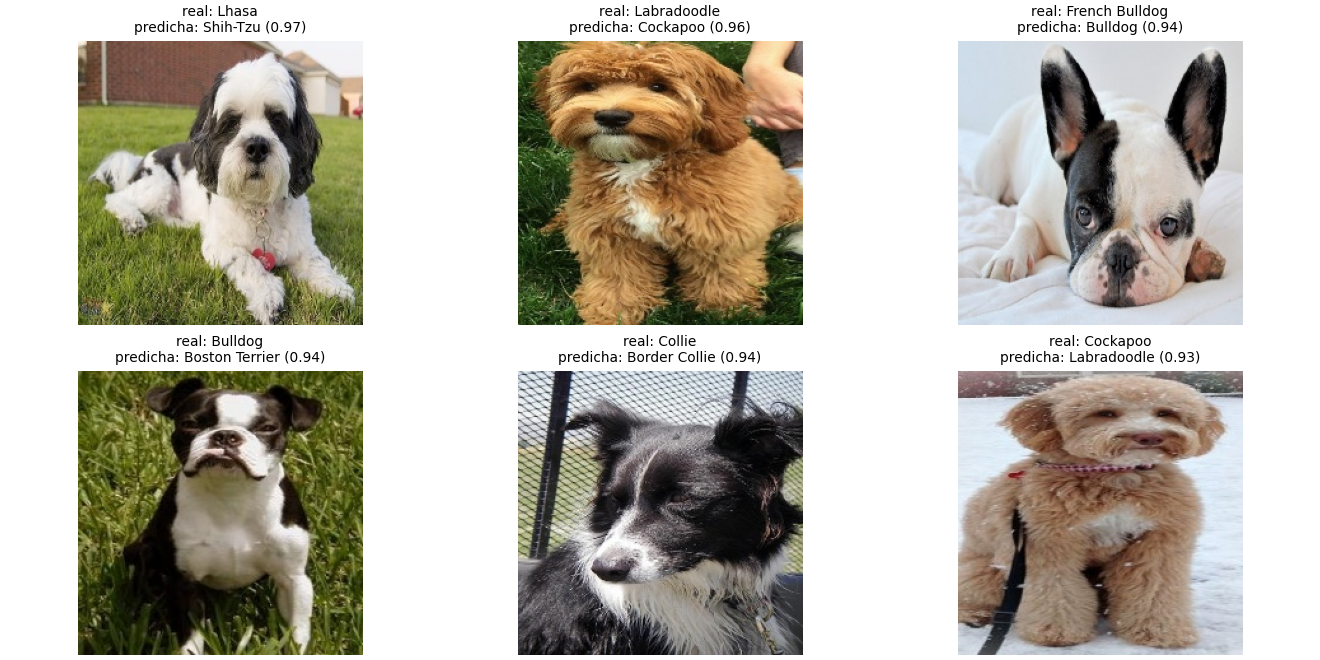

In [29]:
figure = Figure(figsize=(12, 6), layout="constrained")
axes = figure.subplots(2, 3)
examples = errors_a.head(6).iter_rows(named=True)
for axis, row in zip(axes.flat, examples):
    axis.imshow(cv2.cvtColor(baseline_image(row["path"]), cv2.COLOR_BGR2RGB))
    axis.set_title(f"real: {row['real']}\npredicha: {row['predicha']} ({row['score']:.2f})", fontsize=9)
    axis.axis("off")
display_baseline_figure(figure, "Errores del Modelo A (mayor confianza)")

## 11. Costo computacional

El tiempo de CPU por imagen se calculó **en lotes de ocho**. Después de una pasada
de calentamiento, se cronometraron tres pasadas sobre el mismo lote sintético y se
dividió el tiempo por las 24 imágenes procesadas. La medición cubre la inferencia
del modelo. Una consulta completa en la app incluye además el preprocesamiento y,
para la búsqueda, la recuperación de vecinos.

El Modelo A ocupó **44,9 MB** y tardó **11,89 ms por imagen**. La CNN ocupó
**5,4 MB** y tardó **19,30 ms por imagen**. En esta prueba, la CNN requirió menos
espacio en disco y más tiempo de CPU por imagen. El extractor baseline tardó
**11,99 ms por imagen**. La tabla registra el tamaño de los checkpoints de los dos
modelos entrenados.

In [30]:
def model_cost(model: torch.nn.Module, name: str, checkpoint: Path | None = None) -> dict:
    """Parámetros, tamaño, latencia en CPU y dimensión del embedding."""
    parameters = sum(parameter.numel() for parameter in model.parameters())
    model = model.cpu().eval()
    batch = torch.zeros(8, 3, settings.image_size, settings.image_size, device="cpu")
    with torch.no_grad():
        model(batch)
        start = time.perf_counter()
        for _ in range(3):
            model(batch)
    milliseconds = 1000 * (time.perf_counter() - start) / (3 * 8)
    return {
        "Modelo": name,
        "Parámetros (M)": parameters / 1e6,
        "Tamaño (MB)": round(checkpoint.stat().st_size / 1e6, 1) if checkpoint else None,
        "ms/imagen CPU": milliseconds,
        "Embedding": getattr(model, "embedding_dim", 512),
    }


from torchvision import models as tv_models

baseline_model = tv_models.resnet18(weights=None)
baseline_model.fc = torch.nn.Identity()
baseline_model.embedding_dim = 512

classifier.set_active_model("resnet18_finetuned")
cost_a = model_cost(
    classifier.load_model(), "Modelo A", settings.model_path / settings.resnet18_model_name
)
classifier.set_active_model("cnn_custom")
cost_b = model_cost(
    classifier.load_model(), "Modelo B", settings.model_path / settings.cnn_custom_model_name
)
cost_baseline = model_cost(baseline_model, "baseline")

with pl.Config(tbl_cols=-1, float_precision=4):
    display(pl.DataFrame([cost_baseline, cost_a, cost_b]))

Modelo,Parámetros (M),Tamaño (MB),ms/imagen CPU,Embedding
str,f64,f64,f64,i64
"""baseline""",11.1765,null,11.9865,512
"""Modelo A""",11.2124,44.9000,11.8938,512
"""Modelo B""",1.3407,5.4000,19.2963,512


## 12. Comparación y elección final

En las filas de los modelos A y B, la accuracy y el F1 macro provienen del
clasificador supervisado de cada modelo. En la fila del baseline, provienen del
voto ponderado de los diez vecinos de la sección 9. Las columnas de NDCG@10
miden el orden de los vecinos recuperados con los embeddings de cada fila.

In [43]:
retrieval_table = {
    (row["Embeddings"], row["Conjunto"]): row for row in retrieval_rows
}
comparison = []
for name in ("Modelo A", "Modelo B"):
    metrics_test = metrics_a if name == "Modelo A" else metrics_b
    metrics_independent = (
        independent_metrics["resnet18_finetuned"]
        if name == "Modelo A"
        else independent_metrics["cnn_custom"]
    )
    cost = cost_a if name == "Modelo A" else cost_b
    comparison.append(
        {
            "Modelo": name,
            "NDCG@10 test": retrieval_table[(name, "test")]["NDCG@10"],
            "NDCG@10 indep": retrieval_table[(name, "independiente")]["NDCG@10"],
            "Accuracy test (%)": 100 * metrics_test["accuracy"],
            "F1 test (%)": 100 * metrics_test["f1"],
            "Accuracy indep (%)": 100 * metrics_independent["accuracy"],
            "F1 indep (%)": 100 * metrics_independent["f1"],
            "Parámetros (M)": cost["Parámetros (M)"],
            "ms/imagen CPU": cost["ms/imagen CPU"],
        }
    )
comparison.append(
    {
        "Modelo": "baseline (Etapa 1)",
        "NDCG@10 test": retrieval_table[("baseline", "test")]["NDCG@10"],
        "NDCG@10 indep": retrieval_table[("baseline", "independiente")]["NDCG@10"],
        "Accuracy test (%)": retrieval_table[("baseline", "test")]["Accuracy de raza (%)"],
        "F1 test (%)": retrieval_table[("baseline", "test")]["F1 macro (%)"],
        "Accuracy indep (%)": retrieval_table[("baseline", "independiente")]["Accuracy de raza (%)"],
        "F1 indep (%)": retrieval_table[("baseline", "independiente")]["F1 macro (%)"],
        "Parámetros (M)": cost_baseline["Parámetros (M)"],
        "ms/imagen CPU": cost_baseline["ms/imagen CPU"],
    }
)
with pl.Config(tbl_cols=-1, float_precision=4):
    display(pl.DataFrame(comparison))

Modelo,NDCG@10 test,NDCG@10 indep,Accuracy test (%),F1 test (%),Accuracy indep (%),F1 indep (%),Parámetros (M),ms/imagen CPU
str,f64,f64,f64,f64,f64,f64,f64,f64
"""Modelo A""",0.8933,0.4977,90.2991,90.4160,50.0000,57.1905,11.2124,11.8938
"""Modelo B""",0.2828,0.0909,37.7097,35.2120,11.7647,16.0000,1.3407,19.2963
"""baseline (Etapa 1)""",0.8374,0.5156,89.3508,89.1185,58.8235,64.7738,11.1765,11.9865


In [44]:
best_classifier = max(("Modelo A", "Modelo B"), key=lambda name: next(row["F1 test (%)"] for row in comparison if row["Modelo"] == name))
best_embeddings = max(
    ("baseline", "Modelo A", "Modelo B"),
    key=lambda name: (
        retrieval_table[(name, "independiente")]["NDCG@10"],
        retrieval_table[(name, "test")]["NDCG@10"],
    ),
)
print(f"Modelo para clasificar: {best_classifier}")
print(f"Embeddings para la búsqueda (EMBEDDING_MODEL): {best_embeddings}")

Modelo para clasificar: Modelo A
Embeddings para la búsqueda (EMBEDDING_MODEL): baseline


- **Clasificación supervisada.** Elegimos la **ResNet18 ajustada (Modelo A)** por
  su mayor F1 macro en test (90,42 % frente a 35,21 % de la CNN). También obtuvo mayor
  F1 macro en el independiente (57,19 % frente a 16,00 %). La estimación
  de rendimiento independiente corresponde a las 20 razas de esa muestra.
- **Búsqueda por similitud.** Elegimos el **baseline preentrenado** por su mayor
  NDCG@10 en las 68 consultas independientes. En test, la ResNet ajustada ordenó
  mejor los vecinos. La preferencia para la app depende de cuánto se parezcan las
  consultas reales a las de la muestra independiente.

## 13. Checkpoints

Extraé el ZIP en la raíz del repositorio. Los clasificadores quedan en `models/resnet18_finetuned.pth` y `models/cnn_custom.pth`, donde los cargan tanto el backend local como Docker. Los dos historiales de entrenamiento quedan en `output/grupos-v1/`. [Descargar modelos e historiales](https://drive.google.com/file/d/1IEZiJIOgRH36_3XirJiNXqvp3fCusKxU/view?usp=drive_link)

In [33]:
sorted(path.name for path in settings.model_path.glob("*.pth"))

['cnn_custom.pth', 'resnet18_finetuned.pth']

## Etapa 3 — Comparación de umbrales del detector YOLO

YOLOv8n localiza perros domésticos (clase COCO `dog`). La ResNet18 ajustada de la
app predice una raza para cada recorte. Primero elegimos el umbral de YOLO en
validación. Después usamos ese valor para probar el flujo completo en fotos
independientes.

### Muestra de validación y regla de elección

Cruzamos las 24 rutas de la revisión anterior con `splits/valid.csv` y conservamos
las cinco que siguen en validación. El prefijo `train/`, `valid/` o `test/` indica
la carpeta original de Kaggle. El manifiesto determina la partición final.

Antes de ver las nuevas predicciones, fijamos una muestra de 24 fotos. Ordenamos
las rutas por el SHA-256 de `42:<ruta>`, con la ruta como desempate. Sumamos la
primera foto de Coyote según ese orden para acompañar al Dhole ya anotado y
completamos con una foto por raza todavía ausente. Revisamos los originales y
contamos perros domésticos visibles. La muestra también incluyó un African Wild
Dog, que contamos como negativo junto con el Dhole y el coyote.

Comparamos 0,15, 0,25 y 0,50 con `DetectionService.detect_dogs` sobre las mismas
fotos. En orden de confianza, una caja acierta si localiza una porción sustancial
y reconocible de la cabeza o el cuerpo de un perro. Cada perro puede contar una
vez. Una caja adicional sobre ese perro es duplicada, una caja sin perro es
falsa y un perro sin caja asignada es una omisión. Encajar dos perros juntos
en una sola caja cuenta como máximo para uno.

Elegimos el umbral con menos omisiones. En caso de empate, usamos la menor suma
de cajas falsas y duplicadas y luego la menor distancia a 0,25. Las salidas se
generaron en CPU con Python 3.12.11, Ultralytics 8.4.218 y PyTorch 2.11.0.

In [45]:
import csv
import json
import sys
from hashlib import sha256
from io import BytesIO
from pathlib import Path
from tempfile import TemporaryDirectory

import cv2
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle

YOLO_RAIZ = Path.cwd()
YOLO_DATASET = YOLO_RAIZ / "data" / "dataset"
YOLO_MODELOS = YOLO_RAIZ / "models"
YOLO_UMBRALES = (0.15, 0.25, 0.50)
YOLO_CONTEOS = ["Perros detectados", "Perros omitidos", "Cajas falsas", "Cajas duplicadas"]

if not (YOLO_RAIZ / "src" / "lib").is_dir():
    raise RuntimeError("Abrí el kernel desde la raíz del repositorio.")

yolo_src = str(YOLO_RAIZ / "src")
if yolo_src not in sys.path:
    sys.path.insert(0, yolo_src)

from lib.bootstrap import build_classifier
from lib.config import Settings
from lib.services.detection_service import DetectionService

yolo_pesos = YOLO_MODELOS / "yolov8n.pt"
if not yolo_pesos.is_file():
    raise FileNotFoundError(yolo_pesos)

yolo_detector = DetectionService(
    classifier=None, yolo_model=str(yolo_pesos), conf_threshold=YOLO_UMBRALES[0], dog_class_id=16
)


def yolo_leer_manifiesto(nombre):
    with (YOLO_RAIZ / "splits" / nombre).open(encoding="utf-8-sig", newline="") as archivo:
        return list(csv.DictReader(archivo))


def yolo_leer_imagen(ruta):
    archivo = YOLO_DATASET / ruta
    imagen = cv2.imread(str(archivo))
    if imagen is None:
        raise FileNotFoundError(archivo)
    return imagen

In [46]:
# Cada anotación contiene las instancias visibles y las cajas de la corrida
# revisadas visualmente. "perro" identifica al único perro de una foto.
YOLO_FOTOS_ANTERIORES = (
    "train/Clumber/055.jpg",
    "train/Shiba Inu/48.jpg",
    "train/Bloodhound/047.jpg",
    "test/Bull Mastiff/04.jpg",
    "train/Great Perenees/72.jpg",
    "train/Bichon Frise/097.jpg",
    "train/Pekinese/102.jpg",
    "train/Basset/006.jpg",
    "train/Beagle/100.jpg",
    "test/Mex Hairless/08.jpg",
    "train/Vizsla/07.jpg",
    "train/Lhasa/120.jpg",
    "train/Poodle/107.jpg",
    "train/Bearded Collie/01.jpg",
    "train/Bull Terrier/063.jpg",
    "train/Cairn/109.jpg",
    "train/Basenji/33.jpg",
    "train/Dhole/056.jpg",
    "train/Chow/068.jpg",
    "train/German Sheperd/101.jpg",
    "train/Coyote/83.jpg",
    "train/Corgi/091.jpg",
    "train/Bluetick/105.jpg",
    "test/Border Collie/07.jpg",
)

YOLO_REVISION_VALIDACION = {
    "train/Pekinese/102.jpg": (('perro',), {(3, 21, 203, 197): 'perro'}),
    "train/Poodle/107.jpg": (('perro',), {(5, 6, 202, 224): 'perro'}),
    "train/Bull Terrier/063.jpg": (('perro',), {}),
    "train/Dhole/056.jpg": ((), {}),
    "train/German Sheperd/101.jpg": (('perro',), {}),
    "train/Coyote/41.jpg": ((), {}),
    "train/Golden Retriever/081.jpg": (('perro',), {}),
    "train/Pomeranian/039.jpg": (('perro',), {(0, 2, 223, 223): 'perro'}),
    "train/Yorkie/26.jpg": (('perro',), {}),
    "train/Bloodhound/036.jpg": (('perro',), {(1, 4, 222, 207): 'perro'}),
    "train/Labradoodle/103.jpg": (('perro',), {(9, 0, 213, 219): 'perro'}),
    "train/Collie/107.jpg": (('perro',), {(21, 1, 223, 223): 'perro'}),
    "train/Greyhound/092.jpg": (('perro',), {}),
    "train/Groenendael/058.jpg": (('perro',), {}),
    "train/Bichon Frise/064.jpg": (('perro',), {}),
    "train/Doberman/096.jpg": (('perro',), {}),
    "train/Labrador/086.jpg": (('perro',), {}),
    "test/Shar_Pei/08.jpg": (('perro',), {(14, 8, 218, 224): 'perro'}),
    "train/Japanese Spaniel/094.jpg": (('perro',), {}),
    "train/American Hairless/15.jpg": (('perro',), {(16, 7, 205, 223): 'perro'}),
    "train/Beagle/056.jpg": (('perro',), {(0, 14, 207, 217): 'perro'}),
    "test/African Wild Dog/10.jpg": ((), {}),
    "train/Komondor/030.jpg": (('perro',), {}),
    "test/Great Dane/10.jpg": (('perro',), {(8, 6, 211, 223): 'perro'}),
}


def yolo_muestra_validacion():
    filas = yolo_leer_manifiesto("valid.csv")
    validas = {fila["path"]: fila["breed"] for fila in filas if fila["split"] == "valid"}
    reutilizadas = [ruta for ruta in YOLO_FOTOS_ANTERIORES if ruta in validas]
    muestra = list(reutilizadas)
    razas = {validas[ruta] for ruta in muestra}
    orden = sorted(validas, key=lambda ruta: (sha256(f"42:{ruta}".encode()).hexdigest(), ruta))

    for raza in ("Dhole", "Coyote"):
        if raza not in razas:
            muestra.append(next(ruta for ruta in orden if validas[ruta] == raza))
            razas.add(raza)

    for ruta in orden:
        if len(muestra) == 24:
            break
        raza = validas[ruta]
        if raza not in razas:
            muestra.append(ruta)
            razas.add(raza)

    if len(muestra) != 24 or set(muestra) != set(YOLO_REVISION_VALIDACION):
        raise ValueError("La muestra cambió. Revisá el manifiesto y las anotaciones.")

    return pd.DataFrame([
        {
            "Ruta": ruta,
            "Clase en Kaggle": validas[ruta],
            "Anotación": "Reutilizada" if ruta in reutilizadas else "Nueva",
            "Perros visibles": len(YOLO_REVISION_VALIDACION[ruta][0]),
        }
        for ruta in muestra
    ])


yolo_muestra = yolo_muestra_validacion()
print(
    f"{len(yolo_muestra)} fotos · {yolo_muestra['Perros visibles'].sum()} perros domésticos · "
    f"{yolo_muestra['Perros visibles'].eq(0).sum()} negativos · "
    f"{yolo_muestra['Anotación'].eq('Reutilizada').sum()} de las 24 fotos ya anotadas"
)
display(yolo_muestra.style.hide(axis="index"))

24 fotos · 21 perros domésticos · 3 negativos · 5 de las 24 fotos ya anotadas


Ruta,Clase en Kaggle,Anotación,Perros visibles
train/Pekinese/102.jpg,Pekinese,Reutilizada,1
train/Poodle/107.jpg,Poodle,Reutilizada,1
train/Bull Terrier/063.jpg,Bull Terrier,Reutilizada,1
train/Dhole/056.jpg,Dhole,Reutilizada,0
train/German Sheperd/101.jpg,German Sheperd,Reutilizada,1
train/Coyote/41.jpg,Coyote,Nueva,0
train/Golden Retriever/081.jpg,Golden Retriever,Nueva,1
train/Pomeranian/039.jpg,Pomeranian,Nueva,1
train/Yorkie/26.jpg,Yorkie,Nueva,1
train/Bloodhound/036.jpg,Bloodhound,Nueva,1


In [47]:
def yolo_iou(caja, referencia):
    x1, y1, x2, y2 = caja
    rx1, ry1, rx2, ry2 = referencia
    interseccion = max(0, min(x2, rx2) - max(x1, rx1)) * max(0, min(y2, ry2) - max(y1, ry1))
    union = (x2 - x1) * (y2 - y1) + (rx2 - rx1) * (ry2 - ry1) - interseccion
    return interseccion / union


def yolo_revisar(ruta, anotacion, detecciones):
    visibles, referencias = anotacion
    asignados, cajas = set(), []
    for deteccion in sorted(detecciones, key=lambda caja: -caja["det_score"]):
        # IoU solo identifica la caja ya revisada ante una leve deriva de píxeles.
        # El acierto se decide en la revisión visual de cada caja.
        destinos = {
            destino for referencia, destino in referencias.items()
            if yolo_iou(deteccion["bbox"], referencia) >= 0.85
        }
        if len(destinos) != 1:
            raise ValueError(f"Revisá la asignación de la caja {deteccion} en {ruta}.")
        destino = destinos.pop()
        if destino not in visibles:
            estado = "Falsa"
        elif destino in asignados:
            estado = "Duplicada"
        else:
            estado = "Acierto"
            asignados.add(destino)
        cajas.append({**deteccion, "Destino": destino, "Estado": estado})

    omitidos = tuple(perro for perro in visibles if perro not in asignados)
    return {
        "Ruta": ruta,
        "Perros visibles": len(visibles),
        "Perros detectados": len(asignados),
        "Perros omitidos": len(omitidos),
        "Cajas falsas": sum(caja["Estado"] == "Falsa" for caja in cajas),
        "Cajas duplicadas": sum(caja["Estado"] == "Duplicada" for caja in cajas),
        "Omitidos": omitidos,
        "Cajas": cajas,
    }


def yolo_dibujar_caja(eje, caja, rotulo, color):
    x1, y1, x2, y2 = caja["bbox"]
    eje.add_patch(Rectangle(
        (x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, lw=2.4
    ))
    eje.annotate(
        rotulo, (x1, y1), xytext=(3, -3), textcoords="offset points",
        va="top", fontsize=11, color="black",
        bbox={"facecolor": color, "edgecolor": "none", "pad": 3},
    )


def yolo_mostrar_figura(figura, titulo):
    with BytesIO() as salida:
        figura.savefig(salida, format="png", dpi=110)
        display(Image(data=salida.getvalue(), format="png", alt=titulo))

,Perros visibles,Perros detectados,Perros omitidos,Cajas falsas,Cajas duplicadas
Umbral,,,,,
0.15,21,10,11,0,0
0.25,21,9,12,0,0
0.50,21,6,15,0,0


Umbral elegido en validación: 0.15


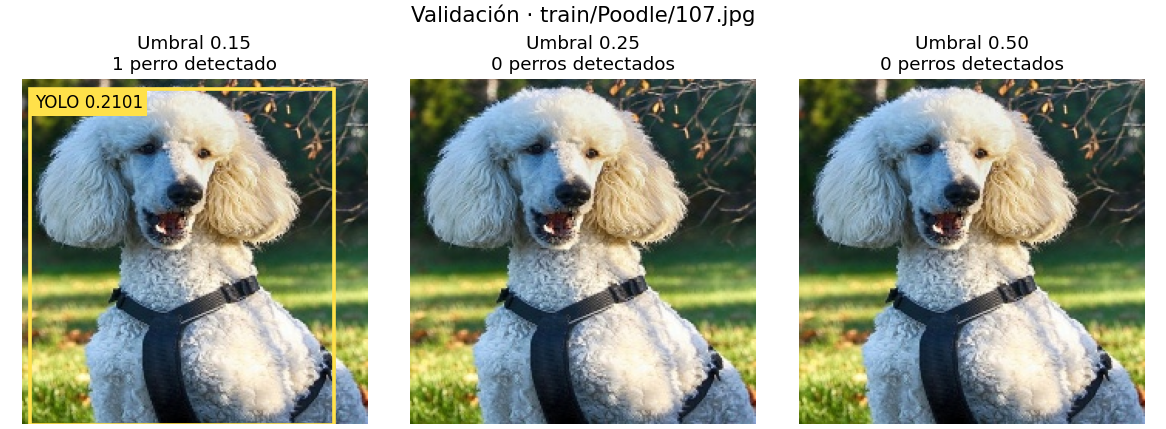

In [48]:
yolo_revision_por_umbral = []
for yolo_ruta in yolo_muestra["Ruta"]:
    yolo_foto = yolo_leer_imagen(yolo_ruta)
    for yolo_umbral in YOLO_UMBRALES:
        yolo_detector.conf_threshold = yolo_umbral
        yolo_cajas = [
            {"bbox": caja, "det_score": conf}
            for caja, conf in yolo_detector.detect_dogs(yolo_foto)
        ]
        yolo_revision_por_umbral.append({
            "Umbral": yolo_umbral,
            **yolo_revisar(yolo_ruta, YOLO_REVISION_VALIDACION[yolo_ruta], yolo_cajas),
        })

yolo_validacion = pd.DataFrame(yolo_revision_por_umbral)
yolo_totales_validacion = yolo_validacion.groupby("Umbral")[["Perros visibles", *YOLO_CONTEOS]].sum()
display(yolo_totales_validacion.style.format_index("{:.2f}", axis=0))
yolo_elegido = min(
    YOLO_UMBRALES,
    key=lambda umbral: (
        yolo_totales_validacion.at[umbral, "Perros omitidos"],
        yolo_totales_validacion.at[umbral, "Cajas falsas"]
        + yolo_totales_validacion.at[umbral, "Cajas duplicadas"],
        abs(umbral - 0.25),
    ),
)
print(f"Umbral elegido en validación: {yolo_elegido:.2f}")


def yolo_comparar_umbrales(ruta):
    original = cv2.cvtColor(yolo_leer_imagen(ruta), cv2.COLOR_BGR2RGB)
    titulo = f"Validación · {ruta}"
    figura = Figure(figsize=(10.6, 3.9), layout="constrained")
    figura.suptitle(titulo, fontsize=14)
    resultados = yolo_validacion.loc[yolo_validacion["Ruta"].eq(ruta)].to_dict("records")
    for eje, resultado in zip(figura.subplots(1, 3), resultados, strict=True):
        eje.imshow(original)
        perros = resultado["Perros detectados"]
        texto = "1 perro detectado" if perros == 1 else f"{perros} perros detectados"
        eje.set_title(f"Umbral {resultado['Umbral']:.2f}\n{texto}")
        eje.set_axis_off()
        for caja in resultado["Cajas"]:
            yolo_dibujar_caja(eje, caja, f"YOLO {caja['det_score']:.4f}", "#ffe14a")
    yolo_mostrar_figura(figura, titulo)


yolo_comparar_umbrales("train/Poodle/107.jpg")

### Qué cambió al bajar el umbral

Con 0,15 se detectaron 10 de los 21 perros y se omitieron 11. Con 0,25 se
detectaron 9 y con 0,50, 6. Los tres umbrales tuvieron cero cajas falsas y
duplicadas en estas 24 fotos. El Poodle de la figura, una foto de validación
cuyo original de Kaggle está bajo `train/`, aparece con una confianza de
0,2101. Solo 0,15 conserva esa caja.

### Detector y clasificador en el conjunto independiente

Usamos solo el umbral elegido en validación. Conservamos 25 fotos anotadas
de un perro y 2 casos ya revisados: la escena con Beagle y Golden Retriever
y un gato. Sumamos por inspección de los originales una escena de dos Huskies
que se tapan entre sí, dos escenas complejas (perro detrás de un sillón con
pelota y perro con un juguete en un mercado) y dos negativos (otro gato y un
peluche). Son 32 fotos distintas del manifiesto. `escena_001.jpg` también
contiene personas, pero se cuenta solo en la categoría de perros superpuestos.

Ejecutamos `DetectionService.predict`, el mismo flujo que usa `/detect`, con
`models/resnet18_finetuned.pth`. Primero revisamos las cajas de YOLO. La tabla de
razas compara la etiqueta del manifiesto con la predicción de la ResNet solo
para perros localizados y etiquetados. Las omisiones, cajas duplicadas y cajas
falsas se cuentan en el detector. El servicio igualmente devuelve una raza para
cada caja que genera, incluso si recortó una persona.

In [49]:
# En escena_006, la única caja abarca a ambos Huskies. Se asigna al de la
# izquierda, cuya cabeza queda completa, y el de la derecha queda sin caja propia.
# En contexto_008, ambas cajas contienen la misma cabeza visible sobre el sillón.
YOLO_REVISION_INDEPENDIENTE = {
    "independent/Beagle/beagle_001.jpg": (('perro',), {(250, 373, 845, 1043): 'perro'}),
    "independent/Beagle/beagle_002.jpg": (('perro',), {(109, 374, 814, 1280): 'perro'}),
    "independent/Bearded Collie/bearded_collie_001.jpg": (('perro',), {(247, 30, 720, 718): 'perro'}),
    "independent/Bearded Collie/bearded_collie_002.jpg": (('perro',), {(133, 104, 805, 1149): 'perro'}),
    "independent/Border Collie/border_collie_001.jpg": (('perro',), {(46, 102, 262, 203): 'perro'}),
    "independent/Border Collie/border_collie_002.jpg": (('perro',), {(26, 270, 380, 646): 'perro'}),
    "independent/Chihuahua/chihuahua_001.jpg": (('perro',), {(109, 76, 559, 520): 'perro'}),
    "independent/Chihuahua/chihuahua_002.jpg": (('perro',), {(144, 105, 801, 395): 'perro'}),
    "independent/Chihuahua/chihuahua_003.jpg": (('perro',), {(143, 40, 1218, 1070): 'perro'}),
    "independent/Cockapoo/cockapoo_001.jpg": (('perro',), {(1, 437, 736, 1331): 'perro'}),
    "independent/Cockapoo/cockapoo_002.jpg": (('perro',), {(241, 132, 818, 1154): 'perro'}),
    "independent/Collie/collie_001.jpg": (('perro',), {(224, 45, 706, 470): 'perro'}),
    "independent/Collie/collie_002.jpg": (('perro',), {(1, 0, 738, 718): 'perro'}),
    "independent/Golden Retriever/golden_retriever_001.jpg": (('perro',), {(1243, 558, 2576, 2255): 'perro'}),
    "independent/Golden Retriever/golden_retriever_002.jpg": (('perro',), {(28, 4, 628, 478): 'perro'}),
    "independent/Labradoodle/labradoodle_001.jpg": (('perro',), {(6, 285, 670, 873): 'perro'}),
    "independent/Labradoodle/labradoodle_002.jpg": (('perro',), {(231, 303, 1246, 1879): 'perro'}),
    "independent/Labrador/labrador_001.jpg": (('perro',), {(195, 739, 3024, 3741): 'perro'}),
    "independent/Labrador/labrador_002.jpg": (('perro',), {}),
    "independent/Pekinese/pekinese_001.jpg": (('perro',), {(62, 153, 757, 674): 'perro'}),
    "independent/Pekinese/pekinese_002.jpg": (('perro',), {(23, 187, 849, 816): 'perro'}),
    "independent/Pomeranian/pomeranian_001.jpg": (('perro',), {(62, 18, 709, 617): 'perro'}),
    "independent/Pomeranian/pomeranian_002.jpg": (('perro',), {(27, 27, 922, 828): 'perro'}),
    "independent/Poodle/Poodle.jpg": (('perro',), {(187, 21, 718, 848): 'perro'}),
    "independent/Poodle/Standard_black_Poodle.jpg": (('perro',), {(197, 15, 408, 425): 'perro'}),
    "independent/escenas/escena_001.jpg": (
        ('Beagle', 'Golden Retriever'),
        {
            (855, 1375, 2709, 3014): "Beagle",
            (1036, 453, 4032, 2755): "Golden Retriever",
            (513, 2, 1234, 1560): "persona del fondo",
        },
    ),
    "independent/escenas/escena_006.jpg": (('Husky de la izquierda', 'Husky de la derecha'), {(310, 422, 2678, 2036): 'Husky de la izquierda'}),
    "independent/escenas/contexto_008.jpg": (
        ('perro',),
        {
            (733, 612, 2133, 1160): "perro",
            (2, 6, 2597, 1288): "perro",
        },
    ),
    "independent/escenas/contexto_009.jpg": (('perro',), {(1412, 784, 2628, 2326): 'perro'}),
    "independent/sin_perro/gato_001.jpg": ((), {}),
    "independent/sin_perro/gato_002.jpg": ((), {}),
    "independent/sin_perro/objeto_001.jpg": ((), {}),
}

YOLO_CASOS = {
    "un_perro": "Un perro",
    "varios_perros": "Perros superpuestos",
    "perro_contexto": "Escena compleja",
    "gato": "Sin perros",
    "objeto_sin_animal": "Sin perros",
}

yolo_manifest = {}
for yolo_fila in yolo_leer_manifiesto("independent_manifest.csv"):
    yolo_manifest.setdefault(yolo_fila["path"], []).append(yolo_fila)

yolo_detector.classifier = build_classifier(Settings(
    model_path=YOLO_MODELOS, resnet18_model_name="resnet18_finetuned.pth", image_size=224,
))
yolo_detector.conf_threshold = yolo_elegido
yolo_revision_independiente = []
with TemporaryDirectory(prefix="tp2-etapa3-") as yolo_temporal:
    for yolo_ruta, yolo_anotacion in YOLO_REVISION_INDEPENDIENTE.items():
        yolo_filas = yolo_manifest[yolo_ruta]
        yolo_caso = YOLO_CASOS[yolo_filas[0]["scene_type"]]
        yolo_etiquetas = tuple(dict.fromkeys(fila["breed"] for fila in yolo_filas if fila["breed"]))
        yolo_resultado = Path(yolo_detector.predict(
            str(YOLO_DATASET / yolo_ruta), Path(yolo_temporal)
        ))
        yolo_respuesta = json.loads(yolo_resultado.read_text(encoding="utf-8"))
        yolo_registro = yolo_revisar(yolo_ruta, yolo_anotacion, yolo_respuesta["detections"])
        for yolo_caja in yolo_registro["Cajas"]:
            yolo_destino = yolo_caja["Destino"]
            yolo_etiqueta = None
            if yolo_destino in yolo_anotacion[0]:
                if len(yolo_etiquetas) == 1:
                    yolo_etiqueta = yolo_etiquetas[0]
                elif yolo_destino in yolo_etiquetas:
                    yolo_etiqueta = yolo_destino
            yolo_caja["Etiqueta"] = yolo_etiqueta
        yolo_revision_independiente.append({
            "Caso": yolo_caso,
            "Etiquetas": ", ".join(yolo_etiquetas) or "—",
            **yolo_registro,
        })

In [50]:
yolo_independiente = pd.DataFrame(yolo_revision_independiente)
yolo_grupos = yolo_independiente.groupby("Caso", sort=False)
yolo_resumen_detector = yolo_grupos[["Perros visibles", *YOLO_CONTEOS]].sum()
yolo_resumen_detector.insert(0, "Fotos", yolo_grupos.size())
yolo_resumen_detector.loc["Total"] = yolo_resumen_detector.sum()

display(Markdown("**Localización por YOLO, revisada visualmente**"))
display(yolo_resumen_detector)

yolo_razas = pd.DataFrame([
    {
        "Caso": foto["Caso"],
        "Coincide": int(caja["breed"] == caja["Etiqueta"]),
        "Distinta": int(caja["breed"] != caja["Etiqueta"]),
    }
    for foto in yolo_revision_independiente
    for caja in foto["Cajas"]
    if caja["Estado"] == "Acierto" and caja["Etiqueta"] is not None
])
yolo_resumen_razas = yolo_razas.groupby("Caso", sort=False)[["Coincide", "Distinta"]].sum()
yolo_resumen_razas["Perros localizados con etiqueta"] = yolo_resumen_razas.sum(axis=1)
yolo_resumen_razas.loc["Total"] = yolo_resumen_razas.sum()
display(Markdown("**Raza predicha por ResNet en perros localizados con etiqueta**"))
display(yolo_resumen_razas)

display(Markdown("**Fotos revisadas**"))
display(yolo_independiente[["Caso", "Ruta", "Etiquetas", "Perros visibles", *YOLO_CONTEOS]].style.hide(axis="index"))

yolo_negativos = yolo_independiente.loc[yolo_independiente["Caso"].eq("Sin perros")]
yolo_respuestas_vacias = yolo_negativos["Cajas"].map(len).eq(0).sum()
print(f"Respuesta del servicio: {yolo_respuestas_vacias}/{len(yolo_negativos)} negativos con detections=[].")

**Localización por YOLO, revisada visualmente**

,Fotos,Perros visibles,Perros detectados,Perros omitidos,Cajas falsas,Cajas duplicadas
Caso,,,,,,
Un perro,25,25,24,1,0,0
Perros superpuestos,2,4,3,1,1,0
Escena compleja,2,2,2,0,0,1
Sin perros,3,0,0,0,0,0
Total,32,31,29,2,1,1


**Raza predicha por ResNet en perros localizados con etiqueta**

,Coincide,Distinta,Perros localizados con etiqueta
Caso,,,
Un perro,17,7,24
Perros superpuestos,3,0,3
Escena compleja,1,1,2
Total,21,8,29


**Fotos revisadas**

Caso,Ruta,Etiquetas,Perros visibles,Perros detectados,Perros omitidos,Cajas falsas,Cajas duplicadas
Un perro,independent/Beagle/beagle_001.jpg,Beagle,1,1,0,0,0
Un perro,independent/Beagle/beagle_002.jpg,Beagle,1,1,0,0,0
Un perro,independent/Bearded Collie/bearded_collie_001.jpg,Bearded Collie,1,1,0,0,0
Un perro,independent/Bearded Collie/bearded_collie_002.jpg,Bearded Collie,1,1,0,0,0
Un perro,independent/Border Collie/border_collie_001.jpg,Border Collie,1,1,0,0,0
Un perro,independent/Border Collie/border_collie_002.jpg,Border Collie,1,1,0,0,0
Un perro,independent/Chihuahua/chihuahua_001.jpg,Chihuahua,1,1,0,0,0
Un perro,independent/Chihuahua/chihuahua_002.jpg,Chihuahua,1,1,0,0,0
Un perro,independent/Chihuahua/chihuahua_003.jpg,Chihuahua,1,1,0,0,0
Un perro,independent/Cockapoo/cockapoo_001.jpg,Cockapoo,1,1,0,0,0


Respuesta del servicio: 3/3 negativos con detections=[].


### Cuatro ejemplos del flujo completo

Cada caja numerada se vincula con la revisión de YOLO y la salida de la
ResNet. La etiqueta de referencia viene del manifiesto.

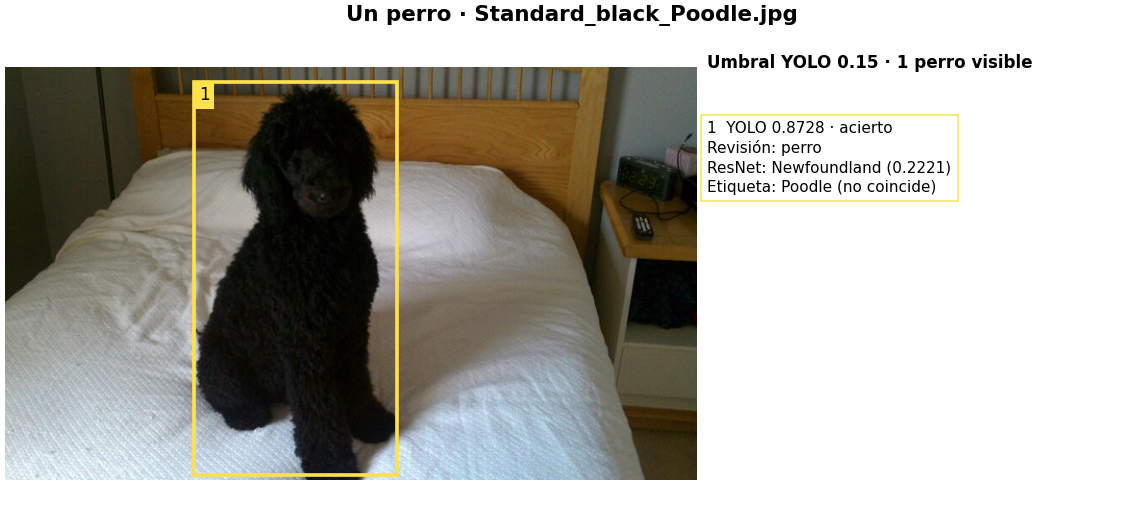

independent/Poodle/Standard_black_Poodle.jpg · Dcac410 · CC BY-SA 3.0. [Fuente](https://commons.wikimedia.org/wiki/File:Standard_black_Poodle.jpg)

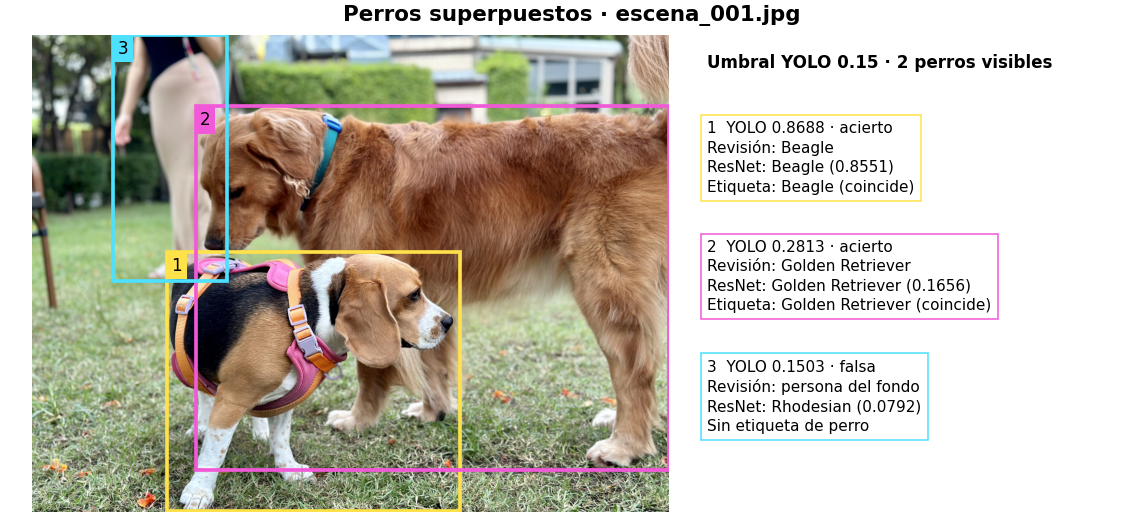

independent/escenas/escena_001.jpg · Slyronit · CC BY-SA 4.0. [Fuente](https://commons.wikimedia.org/wiki/File:A_Golden_Retriever_sniffing_a_Beagle_at_the_Dog_Park.jpg)

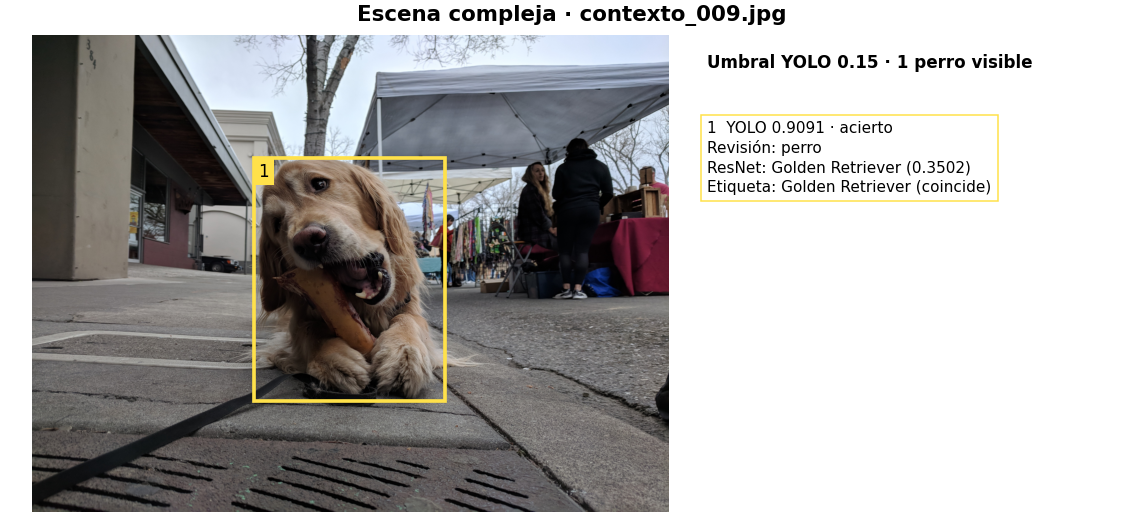

independent/escenas/contexto_009.jpg · Grendelkhan · CC BY-SA 3.0. [Fuente](https://commons.wikimedia.org/wiki/File:Golden_retriever_gnawing_at_the_farmer's_market.jpg)

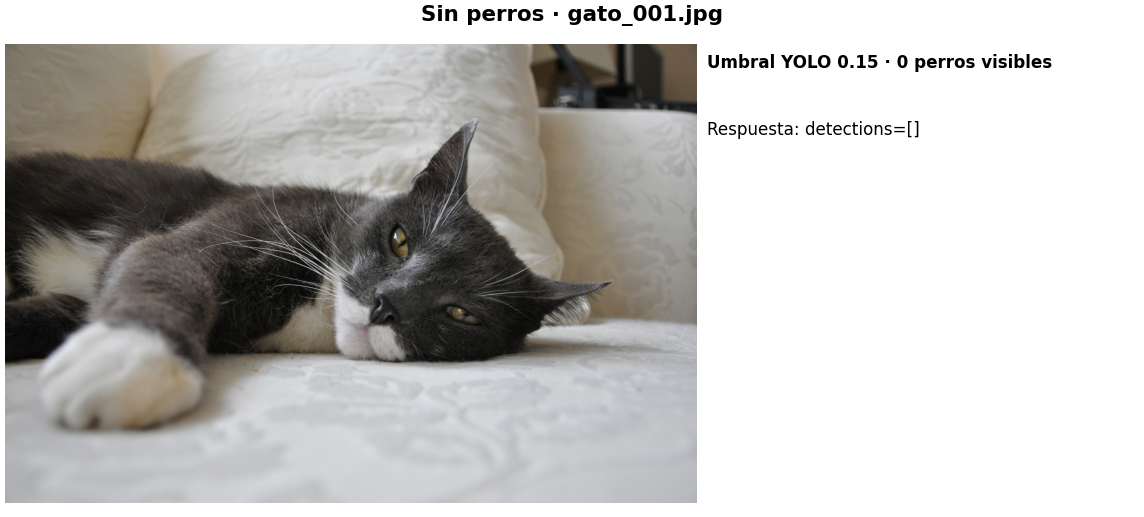

independent/sin_perro/gato_001.jpg · Christoffer G. Thomsen · CC0 1.0. [Fuente](https://commons.wikimedia.org/wiki/File:Cat-on-couch.jpg)

In [51]:
def yolo_mostrar_caso(resultado):
    ruta = resultado["Ruta"]
    original = cv2.cvtColor(yolo_leer_imagen(ruta), cv2.COLOR_BGR2RGB)
    titulo = f"{resultado['Caso']} · {Path(ruta).name}"
    figura = Figure(figsize=(10.4, 4.7), layout="constrained")
    figura.suptitle(titulo, fontsize=14, fontweight="bold")
    foto, detalle = figura.subplots(1, 2, width_ratios=[1.6, 1])
    foto.imshow(original)
    foto.set_axis_off()
    detalle.set_axis_off()
    visibles = resultado["Perros visibles"]
    conteo = "1 perro visible" if visibles == 1 else f"{visibles} perros visibles"
    detalle.text(
        0, 0.96,
        f"Umbral YOLO {yolo_elegido:.2f} · {conteo}",
        transform=detalle.transAxes, fontsize=11, fontweight="bold", va="top",
    )

    colores = ("#ffe14a", "#f259d8")
    for numero, caja in enumerate(resultado["Cajas"], start=1):
        estado = caja["Estado"]
        color = {"Falsa": "#4de0ff", "Duplicada": "#ffa85d"}.get(estado, colores[(numero - 1) % 2])
        yolo_dibujar_caja(foto, caja, str(numero), color)
        raza = caja["breed"]
        etiqueta = caja["Etiqueta"]
        contraste = ("coincide" if raza == etiqueta else "no coincide") if etiqueta else ""
        referencia = f"Etiqueta: {etiqueta} ({contraste})" if etiqueta else "Sin etiqueta de perro"
        detalle.text(
            0, 0.82 - 0.25 * (numero - 1),
            f"{numero}  YOLO {caja['det_score']:.4f} · {estado.lower()}\n"
            f"Revisión: {caja['Destino']}\n"
            f"ResNet: {raza} ({caja['breed_score']:.4f})\n{referencia}",
            transform=detalle.transAxes, fontsize=10, va="top", linespacing=1.35,
            bbox={"facecolor": "white", "edgecolor": color, "pad": 4},
        )

    if not resultado["Cajas"]:
        detalle.text(0, 0.82, "Respuesta: detections=[]", transform=detalle.transAxes, fontsize=11, va="top")

    yolo_mostrar_figura(figura, titulo)
    fuente = yolo_manifest[ruta][0]
    display(Markdown(f"{ruta} · {fuente['author']} · {fuente['license']}. [Fuente]({fuente['source']})"))


yolo_ejemplos = (
    "independent/Poodle/Standard_black_Poodle.jpg",
    "independent/escenas/escena_001.jpg",
    "independent/escenas/contexto_009.jpg",
    "independent/sin_perro/gato_001.jpg",
)
yolo_por_ruta = yolo_independiente.set_index("Ruta", drop=False)
for yolo_ruta in yolo_ejemplos:
    yolo_mostrar_caso(yolo_por_ruta.loc[yolo_ruta])

### Decisión para la app

Mantenemos `YOLO_CONF_THRESHOLD=0.15`. En validación recuperó un perro más que
0,25 y cuatro más que 0,50, con 11 omisiones y sin cajas falsas ni duplicadas en
esa muestra. Aceptamos que la app pueda recortar algo que no es un perro. En la
comprobación independiente, YOLO localizó 29 de 31 perros, devolvió una caja
falsa sobre una persona y duplicó la caja del perro detrás del sillón. Las tres
fotos sin perros devolvieron `detections=[]`. La ResNet acertó 21 de las 29 razas
evaluables y confundió al Poodle negro con Newfoundland pese a una caja correcta.
El umbral se eligió con 24 fotos de validación y se comprobó en 32 fotos
independientes elegidas para cubrir cuatro casos. Los conteos describen esas
muestras y queda por medir el comportamiento en el resto de las escenas.